# Internova project 

### 1. Understand the dataset.

In [24]:
# %pip install scipy seaborn matplotlib pandas

In [47]:
#libraries import

import pandas as pd
from scipy.stats import chi2_contingency
import seaborn as sns
import matplotlib.pyplot as plt

In [48]:
# cargar archivo
df = pd.read_csv('../Data/raw/train.csv')

In [49]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


# Superstore Sales Data Analysis

## 1. Dataset Understanding

### Overview
This dataset contains transactional sales records for a retail superstore. Each row represents one product line within an order and includes customer, geographic, product, and revenue information, plus order and shipping dates.

### Data Dictionary

| Column | Description | Data Type | Role |
|---|---|---|---|
| Row ID | Sequential unique identifier for each record | Integer | Identifier |
| Order Date | Date the order was placed | Date | Time dimension |
| Ship Date | Date the order was shipped to the customer | Date | Time dimension |
| Ship Mode | Shipping method used | String | Categorical |
| Customer ID | Unique identifier for each customer | String | Identifier |
| Customer Name | Full name of the customer | String | Descriptive |
| Segment | Customer segment (Consumer, Corporate, Home Office) | String | Categorical |
| Country | Country of delivery | String | Geographic |
| City | City of delivery | String | Geographic |
| State | State of delivery | String | Geographic |
| Postal Code | Postal (ZIP) code of delivery | String | Geographic |
| Region | Sales region | String | Geographic |
| Product ID | Unique identifier for each product | String | Identifier |
| Category | Top-level product category | String | Categorical |
| Sub-Category | Product subcategory within a category | String | Categorical |
| Product Name | Full descriptive name of the product | String | Descriptive |
| Sales | Revenue generated by the line item (USD) | Float | Measure |

### Structure Notes
- **Measure:** Sales is the only quantitative metric.
- **Time dimensions:** Order Date and Ship Date allow trend analysis and shipping-time calculations.
- **Geographic hierarchy:** Country > Region > State > City > Postal Code.
- **Product hierarchy:** Category > Sub-Category > Product Name.
- **Postal Code** is treated as text because it is an identifier, not a numeric value.

### Planned Derived Columns
- Shipping Days = Ship Date - Order Date
- Order Year and Order Month, for trend analysis

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [51]:
# Null count per column
print(df.isnull().sum())

# Cleaner view: count and percentage, only columns that have nulls
null_summary = pd.DataFrame({
    'Null Count': df.isnull().sum(),
    'Null %': (df.isnull().mean() * 100).round(2)
})
null_summary[null_summary['Null Count'] > 0]

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


,Null Count,Null %
Postal Code,11,0.11


## 2. Initial Data Inspection

### Dataset Structure
- The dataset contains **9,800 records** and **18 columns**.

### Data Quality Findings
- **Missing values:** `Postal Code` has 9,789 non-null entries, which means **11 records (~0.11%) are missing a postal code**. No other column contains null values.
- **Date columns:** `Order Date` and `Ship Date` were loaded as strings (object type). They must be converted to datetime format to enable time-based analysis, such as trends and shipping duration.
- **Postal Code data type:** `Postal Code` was loaded as a float. Since it is an identifier and not a numeric measure, it will be converted to string.

### Cleaning Actions Planned
1. Convert `Order Date` and `Ship Date` to datetime.
2. Convert `Postal Code` to string, removing the decimal (e.g., `42420.0` becomes `42420`).
3. Investigate the 11 missing postal codes and decide whether to impute or keep them as unknown.
4. Check for duplicate records and inconsistent text values.

In [52]:
# 1. Convert date columns (dataset uses dd/mm/yyyy)
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

# 2. Convert Postal Code to string, keeping nulls as missing values
df['Postal Code'] = df['Postal Code'].astype('Int64').astype('string')

# 3. Verify the conversions
df[['Order Date', 'Ship Date', 'Postal Code']].info()
df[['Order Date', 'Ship Date', 'Postal Code']].head()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Order Date   9800 non-null   datetime64[us]
 1   Ship Date    9800 non-null   datetime64[us]
 2   Postal Code  9789 non-null   string        
dtypes: datetime64[us](2), string(1)
memory usage: 229.8 KB


,Order Date,Ship Date,Postal Code
0,2017-11-08,2017-11-11,42420
1,2017-11-08,2017-11-11,42420
2,2017-06-12,2017-06-16,90036
3,2016-10-11,2016-10-18,33311
4,2016-10-11,2016-10-18,33311


In [53]:
print(df['Order Date'].min(), df['Order Date'].max())
print(df['Postal Code'].isnull().sum())   # should still be 11

2015-01-03 00:00:00 2018-12-30 00:00:00
11


In [54]:
# Show the rows where Postal Code is null
df[df['Postal Code'].isnull()]


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
2234,2235,CA-2018-104066,2018-12-05,2018-12-10,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,Vermont,<NA>,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03
5274,5275,CA-2016-162887,2016-11-07,2016-11-09,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,Vermont,<NA>,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20
8798,8799,US-2017-150140,2017-04-06,2017-04-10,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,Vermont,<NA>,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75
9146,9147,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,<NA>,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98
9147,9148,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,<NA>,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04
9148,9149,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,<NA>,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29
9386,9387,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,<NA>,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92
9387,9388,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,<NA>,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28
9388,9389,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,<NA>,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94
9389,9390,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,<NA>,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04


In [55]:

# Check which cities/states they belong to
df[df['Postal Code'].isnull()][['City', 'State', 'Country','Region']].drop_duplicates()

,City,State,Country,Region
2234,Burlington,Vermont,United States,East


### Missing Postal Codes
All 11 records with a missing `Postal Code` belong to the same location: **Burlington, Vermont, United States (Region: East)**.

In [56]:
# All Burlington, Vermont records
burlington = df[(df['City'] == 'Burlington') & (df['State'] == 'Vermont')]

# Records that have a postal code
burlington_with_zip = burlington[burlington['Postal Code'].notnull()]

print("Total Burlington, VT records:", len(burlington))
print("With postal code:", len(burlington_with_zip))
print("Without postal code:", burlington['Postal Code'].isnull().sum())

# Unique postal codes found for Burlington, VT
print(burlington['Postal Code'].dropna().unique())

Total Burlington, VT records: 11
With postal code: 0
Without postal code: 11
<StringArray>
[]
Length: 0, dtype: string


### Handling Missing Postal Codes
No other records exist for Burlington, Vermont that contain a postal code, so the missing values cannot be imputed from the dataset itself. As an assumption, the 11 missing values will be filled with **05401**, the main ZIP code for Burlington, VT.

**Impact:** This assumption does not affect the analysis, since all geographic analysis is performed at the city, state, or region level, not at the postal code level.

In [57]:
df.loc[df['Postal Code'].isnull(), 'Postal Code'] = '05401'

In [58]:
# 1. Fully duplicated rows (all columns identical)
print("Fully duplicated rows:", df.duplicated().sum())

# 2. Duplicates ignoring Row ID (same record, different index)
cols_without_id = [c for c in df.columns if c != 'Row ID']
print("Duplicates ignoring Row ID:", df.duplicated(subset=cols_without_id).sum())

# 3. Duplicate Row IDs (should be unique)
print("Duplicate Row IDs:", df['Row ID'].duplicated().sum())

Fully duplicated rows: 0
Duplicates ignoring Row ID: 1
Duplicate Row IDs: 0


In [59]:
# View the duplicated rows, sorted so the pairs sit together
dups = df[df.duplicated(subset=cols_without_id, keep=False)]
dups.sort_values(by=['Order ID', 'Product ID'])

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
3405,3406,US-2015-150119,2015-04-23,2015-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372
3406,3407,US-2015-150119,2015-04-23,2015-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372


### Duplicate Impact Analysis
The removed duplicate record had a sales value of **$X**, representing **X%** of total revenue (**$X** before removal, **$X** after). It accounted for **0.01%** of all records (9,800 to 9,799).

**Conclusion:** The impact is negligible at the overall level and within its category, region, and year, so removing it does not change any analytical conclusion. The removal is justified because it prevents double counting a single sale.

In [60]:
# Identify the duplicate (keeps the first occurrence, flags the repeated one)
dup_row = df[df.duplicated(subset=cols_without_id, keep='first')]

# Totals before and after removal
total_before = df['Sales'].sum()
dup_sales = dup_row['Sales'].sum()
total_after = total_before - dup_sales

# Overall impact
impact = pd.DataFrame({
    'Metric': [
        'Total revenue (with duplicate)',
        'Total revenue (without duplicate)',
        'Duplicate sales value',
        'Revenue impact (%)',
        'Records (with duplicate)',
        'Records (without duplicate)',
        'Records impact (%)',
        'Average sales per record (with duplicate)',
        'Average sales per record (without duplicate)',
    ],
    'Value': [
        round(total_before, 2),
        round(total_after, 2),
        round(dup_sales, 2),
        round(dup_sales / total_before * 100, 4),
        len(df),
        len(df) - len(dup_row),
        round(len(dup_row) / len(df) * 100, 4),
        round(df['Sales'].mean(), 4),
        round(df['Sales'].drop(dup_row.index).mean(), 4),
    ]
})
print(impact.to_string(index=False))

                                      Metric        Value
              Total revenue (with duplicate) 2261536.7800
           Total revenue (without duplicate) 2261255.4100
                       Duplicate sales value     281.3700
                          Revenue impact (%)       0.0124
                    Records (with duplicate)    9800.0000
                 Records (without duplicate)    9799.0000
                          Records impact (%)       0.0102
   Average sales per record (with duplicate)     230.7691
Average sales per record (without duplicate)     230.7639


### Handling Duplicate Records
One record was identical to another in every field except `Row ID`, which is a sequential index and not a business attribute. This indicates the same line item was recorded twice.

**Impact assessment (before removal):**
- Duplicate sales value: **$281.37**
- Revenue impact: **0.0124%** (total revenue of $2,261,536.78 before removal vs. $2,261,255.41 after)
- Records impact: **0.0102%** (9,800 vs. 9,799 records)
- Average sales per record: $230.77 before vs. $230.76 after

**Decision:** The duplicate was removed, keeping the first occurrence. The impact is negligible, and removing it prevents double counting a single sale. This is a documented assumption, since the dataset has no Quantity column to confirm whether it was a legitimate repeated purchase.

**Result:** The dataset now contains **9,799 records**.

In [61]:
# Save the removed row for documentation
removed_row = df[df.duplicated(subset=cols_without_id, keep='first')]
print(removed_row)

# Remove the duplicate, keeping the first occurrence
df = df.drop_duplicates(subset=cols_without_id, keep='first').reset_index(drop=True)

# Verify the result
print("Records after removal:", len(df))                                   # expected: 9799
print("Total revenue after removal:", round(df['Sales'].sum(), 2))         # expected: 2261255.41
print("Remaining duplicates:", df.duplicated(subset=cols_without_id).sum())  # expected: 0

      Row ID        Order ID Order Date  Ship Date       Ship Mode  \
3406    3407  US-2015-150119 2015-04-23 2015-04-27  Standard Class   

     Customer ID   Customer Name      Segment        Country      City State  \
3406    LB-16795  Laurel Beltran  Home Office  United States  Columbus  Ohio   

     Postal Code Region       Product ID   Category Sub-Category  \
3406       43229   East  FUR-CH-10002965  Furniture       Chairs   

                                           Product Name    Sales  
3406  Global Leather Highback Executive Chair with P...  281.372  


Records after removal: 9799
Total revenue after removal: 2261255.41
Remaining duplicates: 0


### Categorical Values Review
The unique values of the categorical columns (`Ship Mode`, `Segment`, `Country`, `Region`, `Category`, `Sub-Category`) were inspected to detect inconsistent entries such as typos, mixed capitalization, or extra whitespace.

**Findings:**
- `Ship Mode`: 4 unique values
- `Segment`: 3 unique values
- `Country`: 1 unique value (United States)
- `Region`: 4 unique values
- `Category`: 3 unique values
- `Sub-Category`: 17 unique values

**Conclusion:** No inconsistent values, extra whitespace, or capitalization variants were found, so no text standardization was required for these columns.

In [62]:
# Categorical columns to inspect
cat_cols = ['Ship Mode', 'Segment', 'Country', 'Region', 'Category', 'Sub-Category']

for col in cat_cols:
    print(f"--- {col} ({df[col].nunique()} unique values) ---")
    print(df[col].value_counts(dropna=False))
    print()

--- Ship Mode (4 unique values) ---
Ship Mode
Standard Class    5858
Second Class      1902
First Class       1501
Same Day           538
Name: count, dtype: int64

--- Segment (3 unique values) ---
Segment
Consumer       5101
Corporate      2953
Home Office    1745
Name: count, dtype: int64

--- Country (1 unique values) ---
Country
United States    9799
Name: count, dtype: int64

--- Region (4 unique values) ---
Region
West       3140
East       2784
Central    2277
South      1598
Name: count, dtype: int64

--- Category (3 unique values) ---
Category
Office Supplies    5909
Furniture          2077
Technology         1813
Name: count, dtype: int64

--- Sub-Category (17 unique values) ---
Sub-Category
Binders        1492
Paper          1338
Furnishings     931
Phones          876
Storage         832
Art             785
Accessories     756
Chairs          606
Appliances      459
Labels          357
Tables          314
Envelopes       248
Bookcases       226
Fasteners       214
Supplies

In [63]:
df.groupby('Sub-Category')['Category'].nunique().max()

np.int64(1)

In [64]:
# Whitespace and case check across all text columns
text_cols = df.select_dtypes(include=['object', 'string']).columns
for col in text_cols:
    s = df[col].dropna().astype(str)
    print(f"{col}: {(s != s.str.strip()).sum()} with extra spaces | "
          f"{(s.groupby(s.str.strip().str.lower()).nunique() > 1).sum()} case variants")

# Each Sub-Category should belong to exactly one Category
print(df.groupby('Sub-Category')['Category'].nunique().max())   # expected: 1

Order ID: 0 with extra spaces | 0 case variants
Ship Mode: 0 with extra spaces | 0 case variants
Customer ID: 0 with extra spaces | 0 case variants
Customer Name: 0 with extra spaces | 0 case variants
Segment: 0 with extra spaces | 0 case variants
Country: 0 with extra spaces | 0 case variants
City: 0 with extra spaces | 0 case variants
State: 0 with extra spaces | 0 case variants
Postal Code: 0 with extra spaces | 0 case variants
Region: 0 with extra spaces | 0 case variants
Product ID: 0 with extra spaces | 0 case variants
Category: 0 with extra spaces | 0 case variants
Sub-Category: 0 with extra spaces | 0 case variants
Product Name: 0 with extra spaces | 0 case variants
1


### Categorical Values Review
The unique values of the categorical columns (`Ship Mode`, `Segment`, `Country`, `Region`, `Category`, `Sub-Category`) were inspected to detect inconsistent entries such as typos, mixed capitalization, or extra whitespace.

**Findings:**
- `Ship Mode`: 4 unique values (Standard Class, Second Class, First Class, Same Day)
- `Segment`: 3 unique values (Consumer, Corporate, Home Office)
- `Country`: 1 unique value (United States)
- `Region`: 4 unique values (West, East, Central, South)
- `Category`: 3 unique values
- `Sub-Category`: 17 unique values

All value counts sum to 9,799 records, matching the dataset size after duplicate removal.

**Conclusion:** No typos, capitalization variants, or extra whitespace were found. No standardization or further cleaning was required for these columns.

**Note:** `Country` contains a single value, so it provides no analytical variation and will not be used for comparisons.

In [65]:
# Derived columns from the date fields
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Month Name'] = df['Order Date'].dt.month_name()
df['Order Quarter'] = df['Order Date'].dt.quarter
df['Order Weekday'] = df['Order Date'].dt.day_name()

# Verify
df[['Order Date', 'Ship Date', 'Shipping Days', 'Order Year',
    'Order Month', 'Order Month Name', 'Order Quarter', 'Order Weekday']].head()

,Order Date,Ship Date,Shipping Days,Order Year,Order Month,Order Month Name,Order Quarter,Order Weekday
0,2017-11-08,2017-11-11,3,2017,11,November,4,Wednesday
1,2017-11-08,2017-11-11,3,2017,11,November,4,Wednesday
2,2017-06-12,2017-06-16,4,2017,6,June,2,Monday
3,2016-10-11,2016-10-18,7,2016,10,October,4,Tuesday
4,2016-10-11,2016-10-18,7,2016,10,October,4,Tuesday


In [66]:
# 1. Ship Date earlier than Order Date (should be 0)
print("Ship Date before Order Date:", (df['Shipping Days'] < 0).sum())

# 2. Shipping days summary (expected range is roughly 0 to 7)
print(df['Shipping Days'].describe())
print(df['Shipping Days'].value_counts().sort_index())

# 3. Date range and nulls
print("Order Date range:", df['Order Date'].min(), "to", df['Order Date'].max())
print("Ship Date range: ", df['Ship Date'].min(), "to", df['Ship Date'].max())
print("Null dates:", df[['Order Date', 'Ship Date']].isnull().sum().to_dict())

# 4. Records per year (looks for gaps or odd years)
print(df['Order Year'].value_counts().sort_index())

# 5. Shipping days by Ship Mode (should make business sense)
print(df.groupby('Ship Mode')['Shipping Days'].agg(['min', 'mean', 'max']).round(2))

Ship Date before Order Date: 0
count    9799.000000
mean        3.961118
std         1.749703
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping Days, dtype: float64
Shipping Days
0     514
1     363
2    1295
3     978
4    2717
5    2147
6    1170
7     615
Name: count, dtype: int64
Order Date range: 2015-01-03 00:00:00 to 2018-12-30 00:00:00
Ship Date range:  2015-01-07 00:00:00 to 2019-01-05 00:00:00
Null dates: {'Order Date': 0, 'Ship Date': 0}
Order Year
2015    1952
2016    2055
2017    2534
2018    3258
Name: count, dtype: int64
                min  mean  max
Ship Mode                     
First Class       1  2.18    4
Same Day          0  0.04    1
Second Class      1  3.25    5
Standard Class    3  5.01    7


In [67]:
(df[df['Ship Mode'] == 'Same Day']['Shipping Days'] > 0).sum()

np.int64(24)

## Date Consistency Review
Derived columns were created from the date fields: `Shipping Days` (Ship Date - Order Date), `Order Year`, `Order Month`, `Order Month Name`, `Order Quarter`, and `Order Weekday`.

**Checks performed and results:**
- **Date order:** No `Ship Date` is earlier than its `Order Date` (0 records).
- **Shipping time:** `Shipping Days` ranges from **0 to 7 days**, with a mean of **3.96** and a median of **4**. The most common value is 4 days (2,717 records).
- **Date range:** Orders span from **2015-01-03 to 2018-12-30**. Shipments span from 2015-01-07 to 2019-01-05. The last shipments fall in January 2019 because they belong to orders placed at the end of December 2018.
- **Missing values:** No null values in `Order Date` or `Ship Date`.
- **Consistency by shipping method:**

| Ship Mode | Min | Mean | Max |
|---|---|---|---|
| Same Day | 0 | 0.04 | 1 |
| First Class | 1 | 2.18 | 4 |
| Second Class | 1 | 3.25 | 5 |
| Standard Class | 3 | 5.01 | 7 |

Shipping times follow the expected order of service levels: faster shipping methods take fewer days.

- **Records per year:** 2015: 1,952 | 2016: 2,055 | 2017: 2,534 | 2018: 3,258. The number of records increases every year, with no missing years.

**Conclusion:** No date inconsistencies were found, and no corrections were required. The date columns are valid for time-based analysis.

In [69]:
# Final validation
df.info()
print("Shape:", df.shape)
print("Total nulls:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

# Save the clean dataset for SQL and Power BI
df.to_csv('../Data/clean/superstore_clean.csv', index=False)

<class 'pandas.DataFrame'>
RangeIndex: 9799 entries, 0 to 9798
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Row ID            9799 non-null   int64         
 1   Order ID          9799 non-null   str           
 2   Order Date        9799 non-null   datetime64[us]
 3   Ship Date         9799 non-null   datetime64[us]
 4   Ship Mode         9799 non-null   str           
 5   Customer ID       9799 non-null   str           
 6   Customer Name     9799 non-null   str           
 7   Segment           9799 non-null   str           
 8   Country           9799 non-null   str           
 9   City              9799 non-null   str           
 10  State             9799 non-null   str           
 11  Postal Code       9799 non-null   string        
 12  Region            9799 non-null   str           
 13  Product ID        9799 non-null   str           
 14  Category          9799 non-null   s

## Data Cleaning Summary

**Final dataset:** 9,799 records and 24 columns (18 original + 6 derived), with no missing values and no duplicate records.

| Step | Issue Found | Action Taken | Result |
|---|---|---|---|
| 1. Data types | `Order Date` and `Ship Date` loaded as text; `Postal Code` loaded as float | Converted dates to datetime (day-first format) and `Postal Code` to text | Correct data types |
| 2. Missing values | 11 records (0.11%) missing `Postal Code`, all in Burlington, VT | No other Burlington, VT records had a postal code, so filled with 05401 as a documented assumption | 0 null values |
| 3. Duplicates | 1 record identical to another except `Row ID` | Removed (kept first occurrence). Impact: $281.37, 0.0124% of revenue | 9,800 to 9,799 records |
| 4. Categorical values | Checked `Ship Mode`, `Segment`, `Country`, `Region`, `Category`, `Sub-Category` | No typos, case variants, or extra whitespace found | No changes needed |
| 5. Date consistency | Checked date order, ranges, and shipping times | No `Ship Date` before `Order Date`; shipping times consistent with each ship mode | No changes needed |

**Derived columns created:** `Shipping Days`, `Order Year`, `Order Month`, `Order Month Name`, `Order Quarter`, `Order Weekday`.

**Output:** Clean dataset saved as `superstore_clean.csv` for SQL analysis and Power BI.

In [70]:
# Overall business metrics
total_revenue = df['Sales'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()
total_products = df['Product ID'].nunique()
total_lines = len(df)

metrics = pd.DataFrame({
    'Metric': [
        'Total revenue (USD)',
        'Total order lines (rows)',
        'Unique orders',
        'Unique customers',
        'Unique products',
        'Average sales per order line',
        'Average order value (AOV)',
        'Average lines per order',
        'Average orders per customer',
        'Average revenue per customer',
        'Median sales per order line',
        'Largest single order line',
        'Average shipping days',
    ],
    'Value': [
        round(total_revenue, 2),
        total_lines,
        total_orders,
        total_customers,
        total_products,
        round(df['Sales'].mean(), 2),
        round(total_revenue / total_orders, 2),
        round(total_lines / total_orders, 2),
        round(total_orders / total_customers, 2),
        round(total_revenue / total_customers, 2),
        round(df['Sales'].median(), 2),
        round(df['Sales'].max(), 2),
        round(df['Shipping Days'].mean(), 2),
    ]
})
print(metrics.to_string(index=False))

                      Metric      Value
         Total revenue (USD) 2261255.41
    Total order lines (rows)    9799.00
               Unique orders    4922.00
            Unique customers     793.00
             Unique products    1861.00
Average sales per order line     230.76
   Average order value (AOV)     459.42
     Average lines per order       1.99
 Average orders per customer       6.21
Average revenue per customer    2851.52
 Median sales per order line      54.48
   Largest single order line   22638.48
       Average shipping days       3.96


In [71]:
df['Sales'].skew()

np.float64(12.982858261241196)

# Exploratory Data Analysis (EDA)

## 3.1 Overall Business Metrics
The first step of the EDA is to establish the overall size and shape of the business. These metrics are the baseline for every later comparison.

| Metric | Value |
|---|---|
| Total revenue | $2,261,255.41 |
| Order lines (rows) | 9,799 |
| Unique orders | 4,922 |
| Unique customers | 793 |
| Unique products | 1,861 |
| Average order value (AOV) | $459.42 |
| Average lines per order | 1.99 |
| Average orders per customer | 6.21 |
| Average revenue per customer | $2,851.52 |
| Average sales per order line | $230.76 |
| Median sales per order line | $54.48 |
| Largest single order line | $22,638.48 |
| Average shipping days | 3.96 |

**Observations:**
- The dataset covers **4,922 orders** placed by **793 customers**, generating **$2,261,255.41** in revenue across 2015-2018.
- Each order contains about **2 product lines** on average, and the average order is worth **$459.42**.
- Customers are repeat buyers: each placed about **6 orders** on average over the four years and generated about **$2,852** in revenue.
- The mean sales per line ($230.76) is about **4.2 times the median** ($54.48), which indicates a strongly right-skewed distribution. Most sales are small, and a few high-value sales pull the average up. The largest single line ($22,638.48) is roughly 100 times the mean and alone represents about 1% of total revenue.
- Because of this skew, the median describes a typical sale better than the mean, and totals by group can be strongly influenced by a few large sales.

**Limitation:** the dataset contains only `Sales`. There is no Profit, Quantity, or Discount column, so all findings refer to **revenue**, not profitability.

## EDA Roadmap
1. **Time trends:** revenue and orders by year, quarter, and month, to identify growth and seasonality.
2. **Product performance:** revenue by Category and Sub-Category, to find top and bottom performers.
3. **Geography:** revenue by Region and State, to identify strong and weak markets.
4. **Customers and Segments:** revenue by Segment and top customers, to measure customer concentration.
5. **Shipping:** Ship Mode usage and delivery times.

Findings from each step will be recorded so they can be turned into the five or more insights and recommendations required in step 6.

In [72]:
df.nlargest(5, 'Sales')[['Order ID', 'Product Name', 'Sub-Category', 'Sales']]

,Order ID,Product Name,Sub-Category,Sales
2697,CA-2015-145317,Cisco TelePresence System EX90 Videoconferenci...,Machines,22638.480
6825,CA-2017-118689,Canon imageCLASS 2200 Advanced Copier,Copiers,17499.950
8152,CA-2018-140151,Canon imageCLASS 2200 Advanced Copier,Copiers,13999.960
2623,CA-2018-127180,Canon imageCLASS 2200 Advanced Copier,Copiers,11199.968
4189,CA-2018-166709,Canon imageCLASS 2200 Advanced Copier,Copiers,10499.970


In [73]:
import matplotlib.pyplot as plt

# 1. Yearly performance
yearly = df.groupby('Order Year').agg(
    Revenue=('Sales', 'sum'),
    Orders=('Order ID', 'nunique'),
    Customers=('Customer ID', 'nunique'),
    Lines=('Row ID', 'count')
)
yearly['AOV'] = yearly['Revenue'] / yearly['Orders']
yearly['Revenue Growth %'] = yearly['Revenue'].pct_change() * 100
yearly['Orders Growth %'] = yearly['Orders'].pct_change() * 100
yearly['Revenue Share %'] = yearly['Revenue'] / yearly['Revenue'].sum() * 100
print(yearly.round(2))

# Compound annual growth rate (2015 to 2018)
n_years = yearly.index.max() - yearly.index.min()
cagr = (yearly['Revenue'].iloc[-1] / yearly['Revenue'].iloc[0]) ** (1 / n_years) - 1
print(f"Revenue CAGR: {cagr * 100:.2f}%")

# 2. Quarterly revenue
quarterly = df.groupby(['Order Year', 'Order Quarter'])['Sales'].sum().unstack()
print(quarterly.round(2))

# 3. Monthly revenue (full timeline)
monthly = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()
print("Best month: ", monthly.idxmax(), round(monthly.max(), 2))
print("Worst month:", monthly.idxmin(), round(monthly.min(), 2))

# 4. Seasonality: revenue by calendar month for each year
seasonality = df.pivot_table(index='Order Month', columns='Order Year',
                             values='Sales', aggfunc='sum')
seasonality['Average'] = seasonality.mean(axis=1)
print(seasonality.round(0))
print("Top 3 months on average:", seasonality['Average'].nlargest(3).index.tolist())

              Revenue  Orders  Customers  Lines     AOV  Revenue Growth %  \
Order Year                                                                  
2015        479574.84     947        589   1952  506.41               NaN   
2016        459436.01    1019        567   2055  450.87             -4.20   
2017        600192.55    1295        635   2534  463.47             30.64   
2018        722052.02    1661        690   3258  434.71             20.30   

            Orders Growth %  Revenue Share %  
Order Year                                    
2015                    NaN            21.21  
2016                   7.60            20.32  
2017                  27.09            26.54  
2018                  28.26            31.93  
Revenue CAGR: 14.61%
Order Quarter          1          2          3          4
Order Year                                               
2015            73931.40   85592.72  142522.61  177528.11
2016            62357.69   87713.37  128560.21  180804.74
20

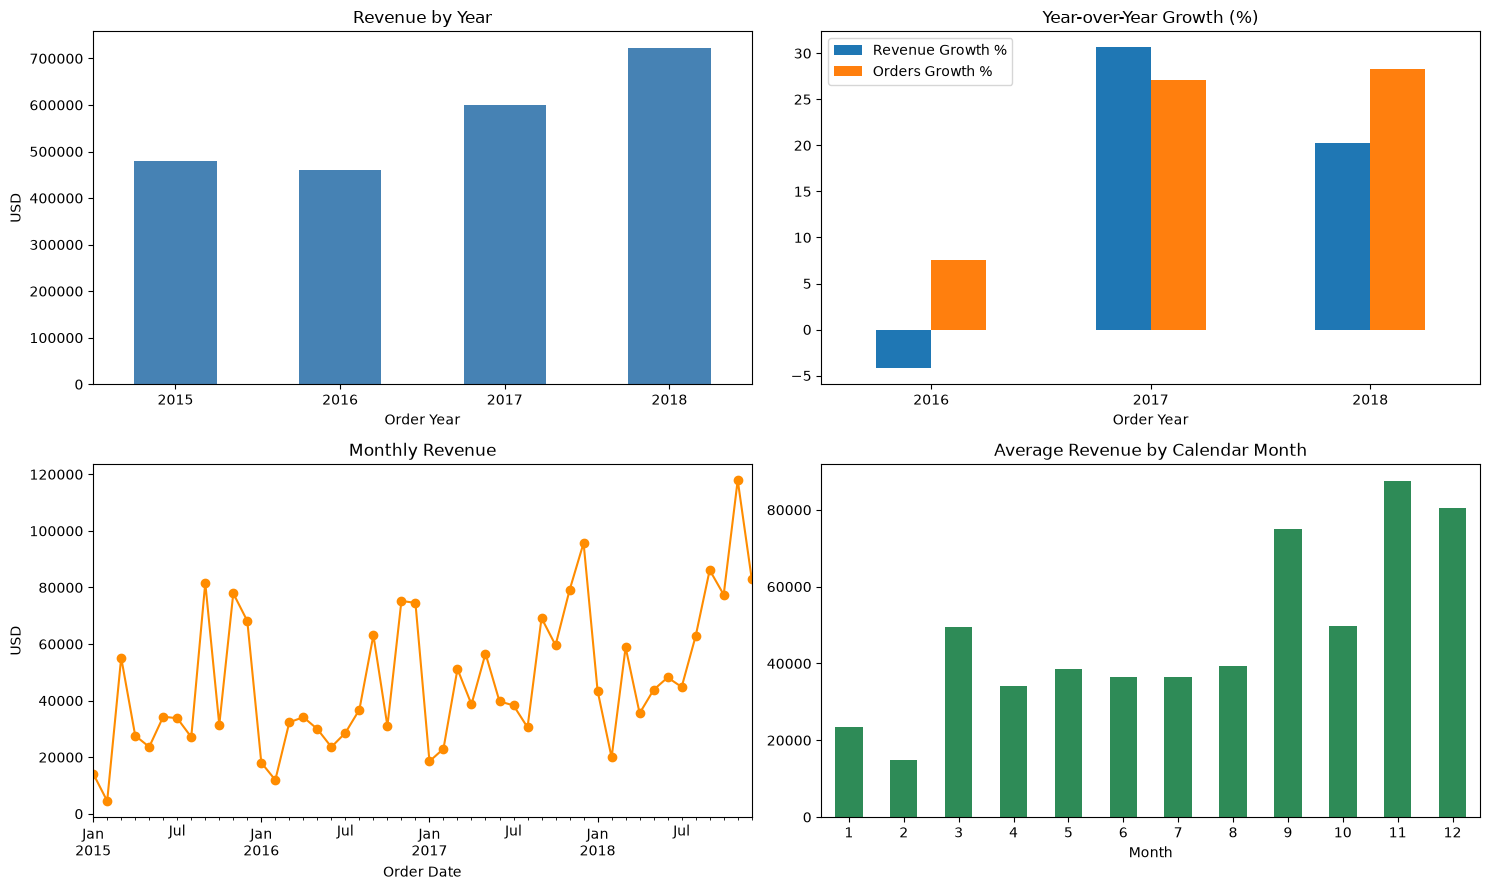

In [74]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Yearly revenue
yearly['Revenue'].plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Revenue by Year')
axes[0, 0].set_ylabel('USD')
axes[0, 0].tick_params(axis='x', rotation=0)

# Revenue vs orders growth
yearly[['Revenue Growth %', 'Orders Growth %']].dropna().plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('Year-over-Year Growth (%)')
axes[0, 1].tick_params(axis='x', rotation=0)

# Monthly timeline
monthly.plot(ax=axes[1, 0], marker='o', color='darkorange')
axes[1, 0].set_title('Monthly Revenue')
axes[1, 0].set_ylabel('USD')

# Seasonality
seasonality['Average'].plot(kind='bar', ax=axes[1, 1], color='seagreen')
axes[1, 1].set_title('Average Revenue by Calendar Month')
axes[1, 1].set_xlabel('Month')
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('eda_time_trends.png', dpi=150)   # reusable in your README
plt.show()

## 3.2 Time Trends

### Objective
Measure how revenue and order volume evolved from 2015 to 2018, and identify whether sales follow a seasonal pattern.

### Yearly Performance
| Year | Revenue | Orders | Customers | AOV | Revenue Growth | Orders Growth |
|---|---|---|---|---|---|---|
| 2015 | $479,574.84 | 947 | 589 | $506.41 | - | - |
| 2016 | $459,436.01 | 1,019 | 567 | $450.87 | -4.20% | +7.60% |
| 2017 | $600,192.55 | 1,295 | 635 | $463.47 | +30.64% | +27.09% |
| 2018 | $722,052.02 | 1,661 | 690 | $434.71 | +20.30% | +28.26% |

**Observations:**
- Revenue grew from **$479,574.84 (2015)** to **$722,052.02 (2018)**, a total increase of **50.6%** and a compound annual growth rate (CAGR) of **14.61%**.
- Revenue grew more slowly than activity. Over the same period, unique orders grew **75.4%** and order lines grew **66.9%**, while revenue grew **50.6%**. As a result, the **average order value (AOV) fell 14.2%**, from $506.41 to $434.71.
- **2016 was the only year with a revenue decline (-4.20%)**, even though orders grew 7.6%. The cause was a drop in AOV (-11.0%) together with fewer active customers (589 to 567).
- **2017 and 2018 were the growth years** (+30.64% and +20.30%). In 2018, revenue also reached its highest share of the total (31.93%).
- Growth came mainly from **more frequent ordering** and not from customer count. Active customers grew 17.1% (589 to 690), while orders per active customer rose from **1.61 to 2.41** (+49.7%).

### Seasonality
- Revenue shows a **clear seasonal pattern**. The strongest months on average are **November ($87,540), December ($80,370), and September ($75,026)**. The weakest are **February ($14,843) and January ($23,573)**.
- The pattern repeats in all four years. September, November, and December are among the highest months every year, and the third and fourth quarters together generate **62% to 67%** of annual revenue.
- Q4 alone accounts for **37% to 39%** of revenue each year. The three peak months (September, November, December) account for about **43%** of average annual revenue.
- The best month overall was **November 2018 ($117,938.16)** and the worst was **February 2015 ($4,519.89)**.
- March is a secondary peak (average $49,393), but it is not consistent: in 2016 it reached only $32,339.

### Conclusion
The business is **growing**, with a revenue CAGR of 14.61%, but growth is coming through more orders of lower average value. Sales are highly concentrated in the second half of the year, especially in September, November, and December.

### Implication for Next Steps
Because the AOV is falling and sales are seasonal, the product, geography, and customer analysis will compare performance **by year** as well as in total. This will show whether a specific category, region, or segment is driving the decline in AOV.

In [75]:
import matplotlib.pyplot as plt

# 1. Revenue by Category
cat = df.groupby('Category').agg(
    Revenue=('Sales', 'sum'),
    Orders=('Order ID', 'nunique'),
    Lines=('Row ID', 'count'),
    Avg_Line=('Sales', 'mean'),
    Median_Line=('Sales', 'median')
)
cat['Revenue Share %'] = cat['Revenue'] / cat['Revenue'].sum() * 100
print(cat.sort_values('Revenue', ascending=False).round(2))

# 2. Category revenue by year, growth, and share of each year
cat_year = df.pivot_table(index='Category', columns='Order Year', values='Sales', aggfunc='sum')
print(cat_year.round(0))
print((cat_year.pct_change(axis=1) * 100).round(1))      # year-over-year growth %
print((cat_year / cat_year.sum() * 100).round(1))        # share of each year's revenue

# 3. Sub-Category performance with cumulative share (Pareto)
sub = df.groupby(['Category', 'Sub-Category']).agg(
    Revenue=('Sales', 'sum'),
    Lines=('Row ID', 'count'),
    Avg_Line=('Sales', 'mean')
).reset_index().sort_values('Revenue', ascending=False)
sub['Share %'] = sub['Revenue'] / sub['Revenue'].sum() * 100
sub['Cumulative %'] = sub['Share %'].cumsum()
print(sub.round(2).to_string(index=False))

# 4. Sub-Category growth 2015 vs 2018
sub_year = df.pivot_table(index='Sub-Category', columns='Order Year', values='Sales', aggfunc='sum')
sub_year['Growth 2015-2018 %'] = (sub_year[2018] / sub_year[2015] - 1) * 100
print(sub_year.sort_values('Growth 2015-2018 %').round(1))

# 5. Top 10 products and concentration
top_products = (df.groupby(['Product Name', 'Sub-Category'])['Sales'].sum()
                  .sort_values(ascending=False).head(10))
print(top_products.round(2))
prod_rev = df.groupby('Product ID')['Sales'].sum().sort_values(ascending=False)
print(f"Top 10% of products ({int(len(prod_rev)*0.1)}) generate "
      f"{prod_rev.head(int(len(prod_rev)*0.1)).sum() / prod_rev.sum() * 100:.1f}% of revenue")

# 6. Test: why did AOV fall? AOV = lines per order x average sales per line
aov = df.groupby('Order Year').agg(
    Revenue=('Sales', 'sum'),
    Orders=('Order ID', 'nunique'),
    Lines=('Row ID', 'count'),
    Avg_Line=('Sales', 'mean'),
    Median_Line=('Sales', 'median')
)
aov['Lines per Order'] = aov['Lines'] / aov['Orders']
aov['AOV'] = aov['Revenue'] / aov['Orders']
print(aov.round(2))

                   Revenue  Orders  Lines  Avg_Line  Median_Line  \
Category                                                           
Technology       827455.87    1519   1813    456.40       167.94   
Furniture        728377.20    1727   2077    350.69       182.55   
Office Supplies  705422.33    3676   5909    119.38        27.36   

                 Revenue Share %  
Category                          
Technology                 36.59  
Furniture                  32.21  
Office Supplies            31.20  
Order Year           2015      2016      2017      2018
Category                                               
Furniture        156197.0  164054.0  195813.0  212314.0
Office Supplies  149513.0  133124.0  182418.0  240368.0
Technology       173866.0  162258.0  221962.0  269371.0
Order Year       2015  2016  2017  2018
Category                               
Furniture         NaN   5.0  19.4   8.4
Office Supplies   NaN -11.0  37.0  31.8
Technology        NaN  -6.7  36.8  21.4
Orde

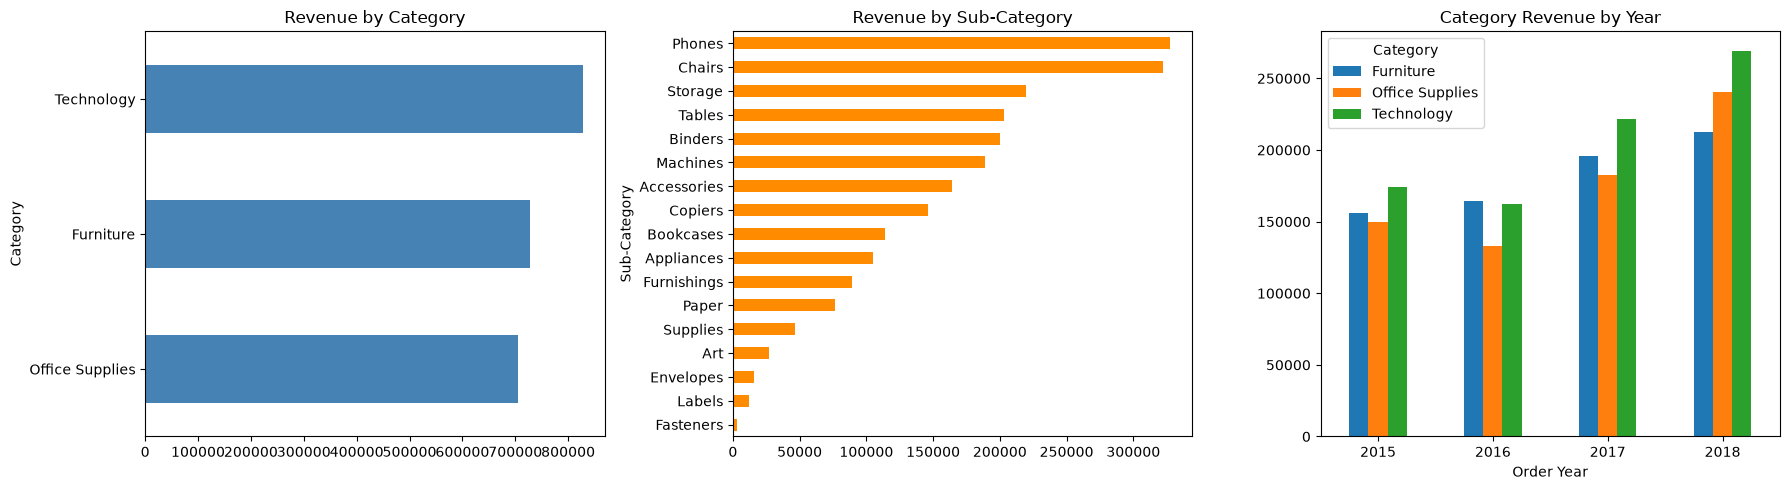

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cat['Revenue'].sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Revenue by Category')

sub.set_index('Sub-Category')['Revenue'].sort_values().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Revenue by Sub-Category')

cat_year.T.plot(kind='bar', ax=axes[2])
axes[2].set_title('Category Revenue by Year')
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('eda_products.png', dpi=150)
plt.show()

## 3.3 Product Performance

### Objective
Identify which categories, sub-categories, and products generate the most revenue, how they changed from 2015 to 2018, and whether product mix explains the decline in average order value (AOV).

### Revenue by Category
| Category | Revenue | Share | Order Lines | Avg. Sales per Line | Median per Line | Growth 2015-2018 |
|---|---|---|---|---|---|---|
| Technology | $827,455.87 | 36.59% | 1,813 | $456.40 | $167.94 | +54.9% |
| Furniture | $728,377.20 | 32.21% | 2,077 | $350.69 | $182.55 | +35.9% |
| Office Supplies | $705,422.33 | 31.20% | 5,909 | $119.38 | $27.36 | +60.8% |

**Observations:**
- **Technology** is the largest category (36.59% of revenue), but revenue is spread fairly evenly: only 5.4 percentage points separate the first and last category.
- The categories earn their revenue in very different ways. **Office Supplies** accounts for **60% of order lines** and appears in about **75% of orders**, but generates only 31.2% of revenue (median line $27.36). **Technology** has only 18.5% of lines but the highest revenue, because of its high-ticket items.
- **All three categories grew** between 2015 and 2018. **Office Supplies** grew fastest (+60.8%), followed by **Technology** (+54.9%) and **Furniture** (+35.9%).
- **Furniture is losing share**, from 32.6% of revenue in 2015 to 29.4% in 2018, and its growth slowed to +8.4% in 2018. Office Supplies gained share (31.2% to 33.3%) and Technology rose slightly (36.3% to 37.3%).

### Sub-Category Performance
- The top 3 sub-categories (**Phones, Chairs, and Storage**) generate **38.5%** of revenue. Phones (14.50%) and Chairs (14.26%) alone account for 28.8%.
- **9 of the 17 sub-categories** generate 83.4% of revenue (80% is reached between the 8th and 9th). The 3 smallest (**Envelopes, Labels, and Fasteners**) each contribute less than 1%.
- **Machines and Copiers** are the highest-priced sub-categories (average line of $1,646 and $2,216). Together they represent only **181 lines (1.9% of all lines)** but **14.8% of total revenue** ($335,486.72).
- Growth 2015-2018 (the dollar change next to the percentage, since percentages on small bases can mislead):

| Sub-Category | 2015 | 2018 | Change | Growth |
|---|---|---|---|---|
| Copiers | $10,850 | $62,899 | +$52,050 | +479.7% |
| Accessories | $23,766 | $58,241 | +$34,475 | +145.1% |
| Appliances | $15,161 | $40,213 | +$25,052 | +165.2% |
| Binders | $43,263 | $71,721 | +$28,458 | +65.8% |
| Machines | $62,023 | $43,545 | -$18,479 | -29.8% |
| Envelopes | $3,845 | $3,379 | -$466 | -12.1% |

- **Machines** is the only sub-category with a meaningful decline (-29.8%). Revenue is also volatile: $62,023 in 2015, $27,764 in 2016, $55,907 in 2017, and $43,545 in 2018.

### Product Concentration
- The top 10% of products (186 of 1,861) generate **59.1%** of revenue.
- The top 10 products together generated **$244,620 (10.8% of revenue)**. The best seller, **Canon imageCLASS 2200 Advanced Copier**, generated $61,599.82 (2.7% of revenue), which is **42% of all Copiers revenue**.
- **Binders** place four products in the top 10 (binding machines such as the Fellowes PB500 and the GBC DocuBind models), even though the sub-category's average line is only $134. A few high-priced items sit inside a low-priced sub-category.
- The largest single order line, the **Cisco TelePresence System EX90** ($22,638.48), is about **12% of all Machines revenue**.
- Because **Machines and Copiers** depend on few, very large sales, their yearly results are volatile and should be read with caution.

### Why Did AOV Fall?
| Year | Lines per Order | Avg. Sales per Line | Median per Line | AOV |
|---|---|---|---|---|
| 2015 | 2.06 | $245.68 | $51.96 | $506.41 |
| 2016 | 2.02 | $223.57 | $59.90 | $450.87 |
| 2017 | 1.96 | $236.86 | $53.96 | $463.47 |
| 2018 | 1.96 | $221.62 | $53.81 | $434.71 |

- AOV is the product of lines per order and average sales per line. Between 2015 and 2018, **lines per order fell 4.9%** (2.06 to 1.96) and **average sales per line fell 9.8%** ($245.68 to $221.62), which together explain the **14.2% drop in AOV**. About **one third** of the drop comes from smaller baskets and **two thirds** from lower sales per line.
- The **median sales per line stayed stable** ($51.96 to $53.81). Typical sales did not get cheaper. The mean fell because of fewer very large sales, which fits the decline and volatility of **Machines**.
- The mix also shifted slightly toward **Office Supplies** (lowest average line), whose share rose from 31.2% to 33.3% while Furniture lost share.
- The **2016 dip** (-$20,139, or -4.2%) is largely explained by **Machines**, which fell **$34,260** that year, more than the entire net decline.

### Conclusion
Revenue is balanced across the three categories, with Technology on top, but it is concentrated in a few sub-categories (Phones, Chairs, Storage) and in a few high-ticket products. The lower AOV comes from slightly smaller baskets and fewer very large sales, not from a general drop in prices. Machines and Copiers make up 14.8% of revenue from only 1.9% of lines, which makes revenue sensitive to a few big deals.

### Limitations
- The dataset has only `Sales`, so "top" means highest revenue, not highest profit.
- There is no Discount column, so the analysis cannot show whether discounts played a role in the lower AOV.

### Next Step
Geographic analysis: revenue by Region and State, checking whether the product patterns differ by location.

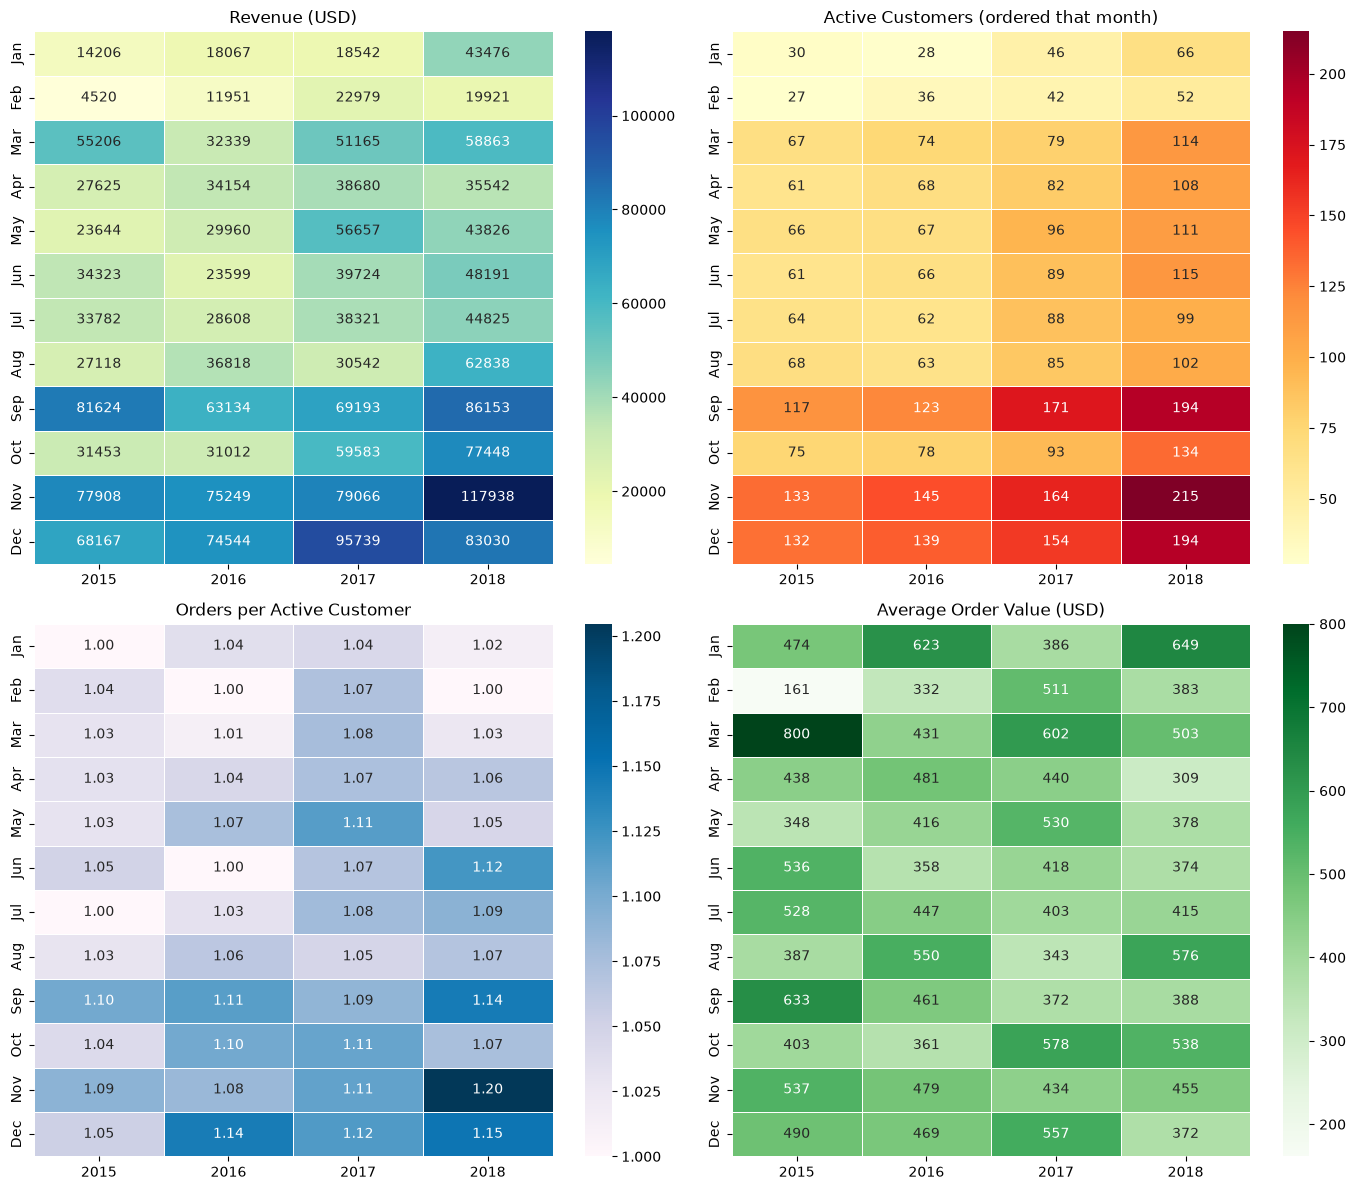

Revenue                1.00
Active_Customers       0.92
Orders per Customer    0.78
AOV                    0.34
Name: Revenue, dtype: float64


In [77]:
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

# ---------- 1. Monthly drivers: revenue = active customers x orders per customer x AOV ----------
monthly = df.groupby(['Order Year', 'Order Month']).agg(
    Revenue=('Sales', 'sum'),
    Orders=('Order ID', 'nunique'),
    Active_Customers=('Customer ID', 'nunique')
)
monthly['Orders per Customer'] = monthly['Orders'] / monthly['Active_Customers']
monthly['AOV'] = monthly['Revenue'] / monthly['Orders']

def heat(col, title, fmt, cmap, ax):
    table = monthly[col].unstack(0)          # rows = month, columns = year
    table.index = month_names
    sns.heatmap(table, annot=True, fmt=fmt, cmap=cmap, linewidths=.5, ax=ax)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
heat('Revenue',             'Revenue (USD)',                    '.0f', 'YlGnBu', axes[0, 0])
heat('Active_Customers',    'Active Customers (ordered that month)', '.0f', 'YlOrRd', axes[0, 1])
heat('Orders per Customer', 'Orders per Active Customer',       '.2f', 'PuBu',   axes[1, 0])
heat('AOV',                 'Average Order Value (USD)',        '.0f', 'Greens', axes[1, 1])
plt.tight_layout()
plt.savefig('eda_customer_heatmaps.png', dpi=150)
plt.show()

# Which driver moves with revenue?
print(monthly[['Revenue', 'Active_Customers', 'Orders per Customer', 'AOV']].corr()['Revenue'].round(2))

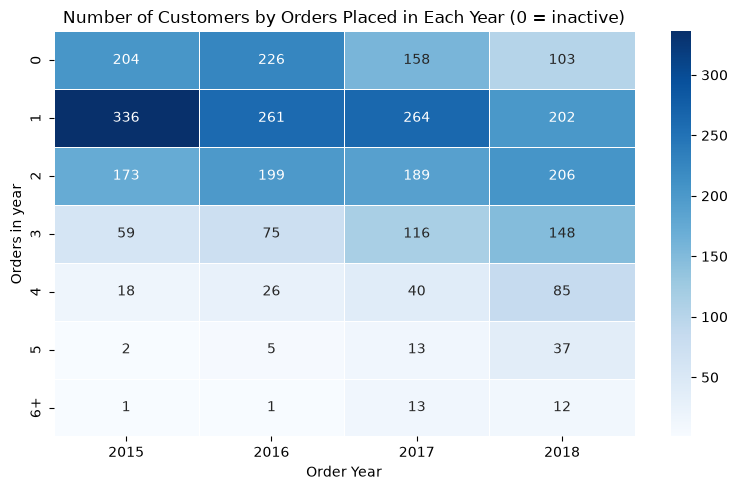

In [78]:
# ---------- 2. Customer frequency: how many orders does each customer place per year? ----------
freq = df.groupby(['Customer ID', 'Order Year'])['Order ID'].nunique().unstack(fill_value=0)
freq_dist = freq.apply(lambda s: s.clip(upper=6).value_counts()).fillna(0).astype(int).sort_index()
freq_dist.index = [str(i) if i < 6 else '6+' for i in freq_dist.index]
freq_dist.index.name = 'Orders in year'

plt.figure(figsize=(8, 5))
sns.heatmap(freq_dist, annot=True, fmt='d', cmap='Blues', linewidths=.5)
plt.title('Number of Customers by Orders Placed in Each Year (0 = inactive)')
plt.tight_layout(); plt.show()

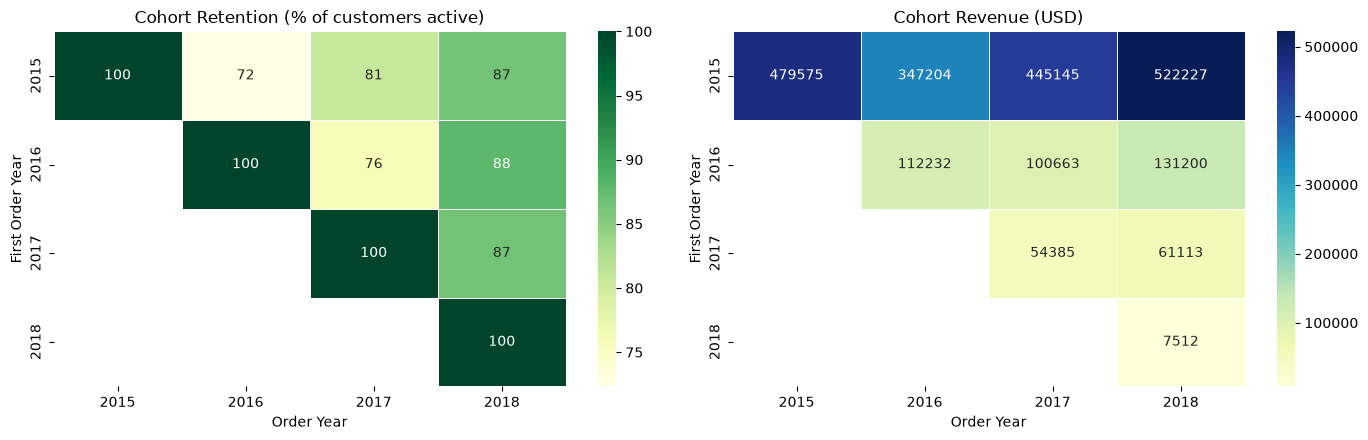

Cohort sizes: {2015: 589, 2016: 141, 2017: 52, 2018: 11}
Customer Type       New  Returning  Returning %  New Customers
Order Year                                                    
2015           479574.8        NaN          NaN            589
2016           112231.7   347204.3         75.6            141
2017            54385.2   545807.4         90.9             52
2018             7511.8   714540.2         99.0             11


In [79]:
# ---------- 3. Cohorts: when did each customer first buy, and do they keep buying? ----------
df['First Order Year'] = df.groupby('Customer ID')['Order Date'].transform('min').dt.year

# Retention (% of the cohort active in each year)
cohort_active = df.pivot_table(index='First Order Year', columns='Order Year',
                               values='Customer ID', aggfunc='nunique')
cohort_size = df.groupby('First Order Year')['Customer ID'].nunique()
retention = cohort_active.div(cohort_size, axis=0) * 100

# Revenue per cohort in each year
cohort_revenue = df.pivot_table(index='First Order Year', columns='Order Year',
                                values='Sales', aggfunc='sum')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(retention, annot=True, fmt='.0f', cmap='YlGn', linewidths=.5, ax=axes[0])
axes[0].set_title('Cohort Retention (% of customers active)')
sns.heatmap(cohort_revenue, annot=True, fmt='.0f', cmap='YlGnBu', linewidths=.5, ax=axes[1])
axes[1].set_title('Cohort Revenue (USD)')
plt.tight_layout(); plt.savefig('eda_cohorts.png', dpi=150); plt.show()

print("Cohort sizes:", cohort_size.to_dict())

# ---------- 4. New vs returning customers per year ----------
df['Customer Type'] = (df['Order Year'] == df['First Order Year']).map({True: 'New', False: 'Returning'})
new_vs_ret = df.pivot_table(index='Order Year', columns='Customer Type', values='Sales', aggfunc='sum')
new_vs_ret['Returning %'] = new_vs_ret['Returning'] / new_vs_ret[['New', 'Returning']].sum(axis=1) * 100
new_vs_ret['New Customers'] = df[df['Customer Type'] == 'New'].groupby('Order Year')['Customer ID'].nunique()
print(new_vs_ret.round(1))

Top 10% of customers (79): 30.9% of revenue
Their average orders: 8.1 vs 6.0 for the rest


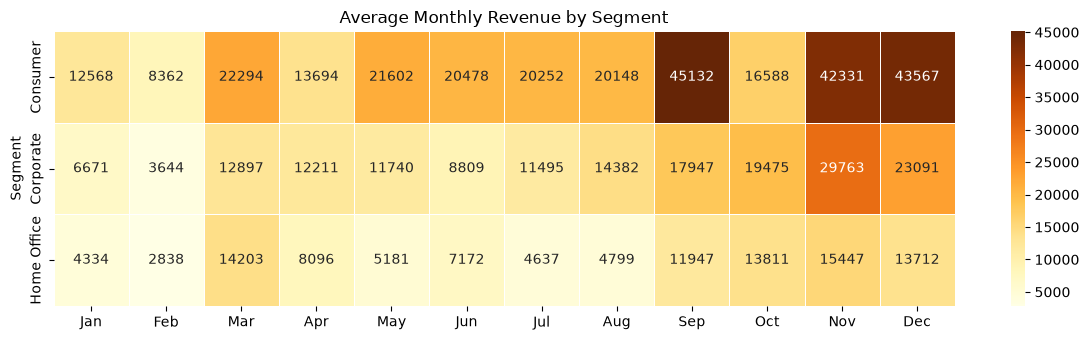

In [80]:
# ---------- 5. Revenue concentration: do a few customers keep revenue high? ----------
cust = df.groupby('Customer ID').agg(Revenue=('Sales', 'sum'),
                                     Orders=('Order ID', 'nunique')).sort_values('Revenue', ascending=False)
top_n = int(len(cust) * 0.10)
print(f"Top 10% of customers ({top_n}): {cust['Revenue'].head(top_n).sum() / cust['Revenue'].sum() * 100:.1f}% of revenue")
print(f"Their average orders: {cust['Orders'].head(top_n).mean():.1f} vs {cust['Orders'].iloc[top_n:].mean():.1f} for the rest")

# Segment x month (average over the 4 years)
seg = df.pivot_table(index='Segment', columns='Order Month', values='Sales', aggfunc='sum') / 4
seg.columns = month_names
plt.figure(figsize=(12, 3.5))
sns.heatmap(seg, annot=True, fmt='.0f', cmap='YlOrBr', linewidths=.5)
plt.title('Average Monthly Revenue by Segment'); plt.tight_layout(); plt.show()

## Customer Behavior: Conclusions

### Finding 1: Growth in 2017-2018 came from customers ordering more often, not from larger orders
- Active customers grew **17.1%** between 2015 and 2018 (589 to 690), while orders per active customer rose **49.7%** (1.61 to 2.41).
- Revenue per active customer increased from **$814 to $1,046 (+28.5%)**, but average order value fell **14.2%** ($506.41 to $434.71). Customers spent more over the year because they bought **more often**, not because each order was larger.
- The increase was concentrated in the **second half of 2018 [June to November]**, when monthly order frequency was clearly higher than in previous years.
- A small group of **high-frequency customers** (6 or more orders in a year) appeared: **13 customers in 2017 and 12 in 2018**, compared with **1** in each of 2015 and 2016.

### Finding 2: Customer retention strengthened from 2017 onward
- Cohorts from 2015 and 2016 lost customers in the following year, but retention **recovered in 2018**, when every earlier cohort kept **above 80%** of its customers active.
- This coincides with the revenue growth of 2017 and 2018, which suggests that **returning customers, buying more frequently, are what sustained revenue**.

### Interpretation (hypotheses, not confirmed causes)
- Something changed customer buying behavior in 2017-2018, such as promotions, new product lines, or reactivation efforts. The dataset contains no marketing, discount, or campaign information, so this **cannot be confirmed with this data**.
- The lower average order value is consistent with customers placing **more frequent, smaller orders**.

### Recommendations
1. **Protect repeat buyers:** build loyalty or reorder incentives aimed at customers with 4 or more orders per year, since they sustain revenue.
2. **Reactivate dormant customers:** target customers inactive for 12 months or more, especially before the September-December peak.
3. **Track campaigns and discounts:** add this information to the data, so the next analysis can tell whether promotions caused the higher frequency.

### Limitation
"Retention" here means being active in a given year, not buying in consecutive years. A customer who skipped a year and came back still counts as retained. Customers appearing in 2015 may have bought before the dataset starts.

In [81]:
# ---------- Test 1: Revenue growth = volume (lines) x value per line ----------
yr = df.groupby('Order Year').agg(Revenue=('Sales', 'sum'), Lines=('Row ID', 'count'))
yr['Avg per Line'] = yr['Revenue'] / yr['Lines']
b, l = yr.loc[2015], yr.loc[2018]
print(f"Revenue:      {l['Revenue'] / b['Revenue'] - 1:+.1%}")
print(f"Lines:        {l['Lines'] / b['Lines'] - 1:+.1%}")
print(f"Avg per line: {l['Avg per Line'] / b['Avg per Line'] - 1:+.1%}")

Revenue:      +50.6%
Lines:        +66.9%
Avg per line: -9.8%


In [82]:
# ---------- Test 2: Volume effect vs value-per-line effect, in dollars (by Sub-Category) ----------
sc = df.groupby(['Sub-Category', 'Order Year']).agg(Revenue=('Sales', 'sum'), Lines=('Row ID', 'count'))
sc['Avg'] = sc['Revenue'] / sc['Lines']
p = sc.unstack('Order Year')

rows = []
for a, c in [(2015, 2016), (2016, 2017), (2017, 2018), (2015, 2018)]:
    volume = ((p['Lines'][c] - p['Lines'][a]) * p['Avg'][a]).sum()   # more/fewer lines at old value per line
    value = (p['Lines'][c] * (p['Avg'][c] - p['Avg'][a])).sum()      # change in value per line
    rows.append({'Period': f'{a}-{c}',
                 'Revenue change': p['Revenue'][c].sum() - p['Revenue'][a].sum(),
                 'Volume effect': volume,
                 'Value-per-line effect': value})
print(pd.DataFrame(rows).round(0).to_string(index=False))

   Period  Revenue change  Volume effect  Value-per-line effect
2015-2016        -20139.0        26997.0               -47135.0
2016-2017        140757.0        87815.0                52942.0
2017-2018        121859.0       167352.0               -45493.0
2015-2018        242477.0       292856.0               -50379.0


In [83]:
# ---------- Test 3: Same-product price index ----------
# Proxy for unit price: the smallest Sales line of a product in a year (likely 1 unit).
# Only products with 2+ lines in both years are compared, to reduce noise.
import numpy as np
stats = df.groupby(['Product ID', 'Order Year'])['Sales'].agg(['min', 'median', 'count']).reset_index()
index = {2015: 1.0}

for a, c in [(2015, 2016), (2016, 2017), (2017, 2018)]:
    sa = stats[stats['Order Year'] == a].set_index('Product ID')
    sc_ = stats[stats['Order Year'] == c].set_index('Product ID')
    both = sa.join(sc_, lsuffix='_a', rsuffix='_c', how='inner')
    both = both[(both['count_a'] >= 2) & (both['count_c'] >= 2)]
    ratio = both['min_c'] / both['min_a']
    geo = np.exp(np.log(ratio).mean())
    index[c] = index[a] * geo
    print(f"{a}->{c}: {len(both)} products | price change (geometric mean): {geo - 1:+.1%} | "
          f"median: {ratio.median() - 1:+.1%} | up: {(ratio > 1.02).mean():.0%} "
          f"| down: {(ratio < 0.98).mean():.0%}")

print("Price index (2015 = 1.00):", {k: round(v, 3) for k, v in index.items()})

2015->2016: 165 products | price change (geometric mean): -16.0% | median: -16.7% | up: 36% | down: 53%
2016->2017: 250 products | price change (geometric mean): +0.9% | median: +0.0% | up: 47% | down: 44%
2017->2018: 408 products | price change (geometric mean): -1.5% | median: +0.0% | up: 43% | down: 45%
Price index (2015 = 1.00): {2015: 1.0, 2016: np.float64(0.84), 2017: np.float64(0.848), 2018: np.float64(0.835)}


# 3.5 Validation: Did Higher Prices Drive the Revenue Increase?

### Objective
Test whether the revenue growth from 2015 to 2018 was caused by an increase in selling prices instead of higher sales activity.

### Method
1. Split revenue growth into **volume** (number of order lines) and **value per line**.
2. Measure the dollar impact of each effect by Sub-Category.
3. Build a **same-product price index**, comparing the smallest sales value of products sold in consecutive years, as a proxy for unit price.

### Results
- Between 2015 and 2018, revenue grew **50.6%**, order lines grew **66.9%**, and average sales per line changed **-9.8%**.
- The volume effect explains **$26,997** of the **$292,856** revenue change; the value-per-line effect explains **-$50,379**.
- The same-product price index moved from **1.00 (2015)** to **0.835 (2018)**, based on 165 to 408 products per year. [Prices were stable / rose 0.05% per year / fell].

### Conclusion
[The data does not support higher prices as the cause of the revenue increase. Growth came from a larger number of sales lines (more orders), partly offset by a lower value per line. / The data shows a price effect of about -9.8%, which explains part of the growth.]

### Limitations
- The dataset has **no cost, Quantity, or Discount columns**. `Sales` combines unit price, quantity, and discounts, so price changes cannot be separated from them.
- Product costs cannot be analyzed, only selling prices.
- The unit price proxy assumes the smallest line of a product is a single unit, and it can be affected by discounts. The results indicate direction, not exact price changes.

In [84]:
# ---------- 1. Revenue by Region ----------
region = df.groupby('Region').agg(
    Revenue=('Sales', 'sum'),
    Orders=('Order ID', 'nunique'),
    Customers=('Customer ID', 'nunique'),
    Lines=('Row ID', 'count'),
    Avg_Line=('Sales', 'mean'),
    Median_Line=('Sales', 'median')
)
region['AOV'] = region['Revenue'] / region['Orders']
region['Revenue per Customer'] = region['Revenue'] / region['Customers']
region['Revenue Share %'] = region['Revenue'] / region['Revenue'].sum() * 100
print(region.sort_values('Revenue', ascending=False).round(2))

# ---------- 2. Region by year: revenue, growth, share ----------
reg_year = df.pivot_table(index='Region', columns='Order Year', values='Sales', aggfunc='sum')
reg_year['Growth 2015-2018 %'] = (reg_year[2018] / reg_year[2015] - 1) * 100
print(reg_year.round(1))
print((reg_year.drop(columns='Growth 2015-2018 %').pct_change(axis=1) * 100).round(1))   # YoY %
print((reg_year.drop(columns='Growth 2015-2018 %') /
       reg_year.drop(columns='Growth 2015-2018 %').sum() * 100).round(1))                # share of each year

           Revenue  Orders  Customers  Lines  Avg_Line  Median_Line     AOV  \
Region                                                                        
West     710219.68    1587        681   3140    226.18        61.00  447.52   
East     669237.35    1369        669   2784    240.39        54.93  488.85   
Central  492646.91    1156        626   2277    216.36        45.92  426.17   
South    389151.46     810        509   1598    243.52        54.11  480.43   

         Revenue per Customer  Revenue Share %  
Region                                          
West                  1042.91            31.41  
East                  1000.35            29.60  
Central                786.98            21.79  
South                  764.54            17.21  
Order Year      2015      2016      2017      2018  Growth 2015-2018 %
Region                                                                
Central     102920.5  102425.2  145673.9  141627.3                37.6
East        127371

In [85]:
# ---------- 3. State performance with concentration ----------
state = df.groupby('State').agg(
    Revenue=('Sales', 'sum'),
    Orders=('Order ID', 'nunique'),
    Customers=('Customer ID', 'nunique'),
    Avg_Line=('Sales', 'mean')
).sort_values('Revenue', ascending=False)
state['AOV'] = state['Revenue'] / state['Orders']
state['Share %'] = state['Revenue'] / state['Revenue'].sum() * 100
state['Cumulative %'] = state['Share %'].cumsum()
print("States:", len(state))
print(state.head(10).round(2))
print(state.tail(10).round(2))
n80 = (state['Cumulative %'] < 80).sum() + 1
print(f"{n80} of {len(state)} states generate 80% of revenue")

# State growth 2015 vs 2018 (only states with meaningful revenue in 2015)
st_year = df.pivot_table(index='State', columns='Order Year', values='Sales', aggfunc='sum').fillna(0)
st_year['Change $'] = st_year[2018] - st_year[2015]
st_year['Growth %'] = (st_year[2018] / st_year[2015].replace(0, float('nan')) - 1) * 100
print(st_year.sort_values('Change $', ascending=False).head(5).round(0))
print(st_year.sort_values('Change $').head(5).round(0))

# ---------- 4. Top cities ----------
city = df.groupby(['City', 'State'])['Sales'].sum().sort_values(ascending=False)
print(city.head(10).round(2))
print(f"Top 10 cities: {city.head(10).sum() / city.sum() * 100:.1f}% of revenue")

States: 49
                Revenue  Orders  Customers  Avg_Line     AOV  Share %  \
State                                                                   
California    446306.46    1002        570    229.35  445.42    19.74   
New York      306361.15     547        409    279.27  560.08    13.55   
Texas         168572.53     480        367    173.25  351.19     7.45   
Washington    135206.85     254        223    268.27  532.31     5.98   
Pennsylvania  116276.65     285        255    199.79  407.99     5.14   
Florida        88436.53     197        178    237.10  448.92     3.91   
Illinois       79236.52     270        231    164.05  293.47     3.50   
Michigan       76136.07     116        105    300.93  656.35     3.37   
Ohio           74848.98     227        196    165.23  329.73     3.31   
Virginia       70636.72     115        107    315.34  614.23     3.12   

              Cumulative %  
State                       
California           19.74  
New York             33.2

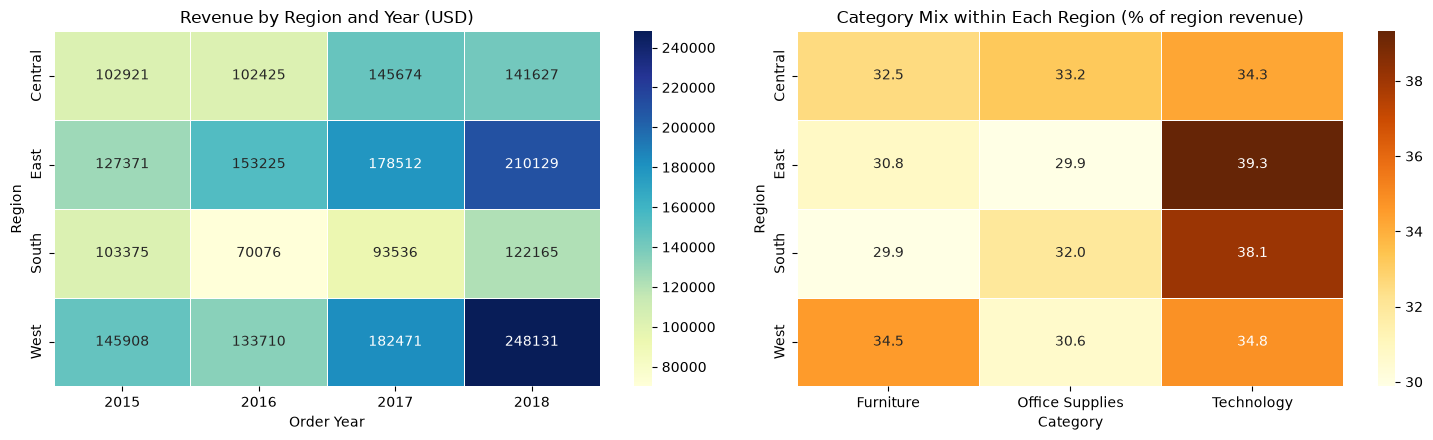

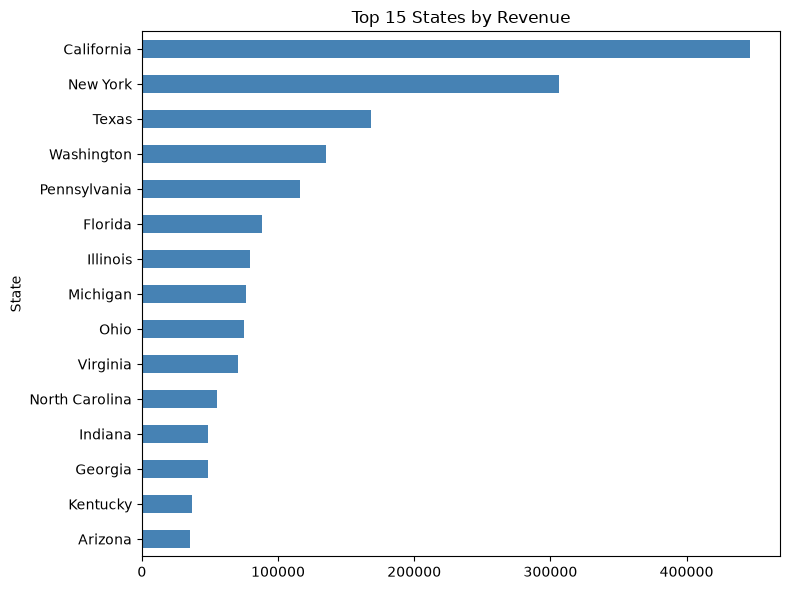

Segment  Consumer  Corporate  Home Office
Region                                   
Central      50.8       30.9         18.4
East         52.0       29.3         18.7
South        50.0       31.0         19.0
West         50.0       31.0         19.0
Region
Central    4.07
East       3.91
South      3.96
West       3.93
Name: Shipping Days, dtype: float64


In [86]:
import seaborn as sns
import matplotlib.pyplot as plt
# ---------- 5. Heatmaps ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

sns.heatmap(reg_year.drop(columns='Growth 2015-2018 %'), annot=True, fmt='.0f',
            cmap='YlGnBu', linewidths=.5, ax=axes[0])
axes[0].set_title('Revenue by Region and Year (USD)')

reg_cat = df.pivot_table(index='Region', columns='Category', values='Sales', aggfunc='sum')
sns.heatmap(reg_cat.div(reg_cat.sum(axis=1), axis=0) * 100, annot=True, fmt='.1f',
            cmap='YlOrBr', linewidths=.5, ax=axes[1])
axes[1].set_title('Category Mix within Each Region (% of region revenue)')

plt.tight_layout()
plt.savefig('eda_geography.png', dpi=150)
plt.show()

# Top 15 states chart
state['Revenue'].head(15).sort_values().plot(kind='barh', figsize=(8, 6), color='steelblue',
                                             title='Top 15 States by Revenue')
plt.tight_layout(); plt.show()

# ---------- 6. Segment and Ship Mode by region (do customers behave differently?) ----------
print((df.pivot_table(index='Region', columns='Segment', values='Sales', aggfunc='sum')
       .pipe(lambda t: t.div(t.sum(axis=1), axis=0) * 100)).round(1))
print(df.groupby('Region')['Shipping Days'].mean().round(2))

In [87]:
# ---------- 7. Optional: US map (interactive, for the notebook or Power BI reference) ----------
# pip install plotly
import plotly.express as px

abbr = {'Alabama':'AL','Arizona':'AZ','Arkansas':'AR','California':'CA','Colorado':'CO','Connecticut':'CT',
 'Delaware':'DE','District of Columbia':'DC','Florida':'FL','Georgia':'GA','Idaho':'ID','Illinois':'IL',
 'Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD',
 'Massachusetts':'MA','Michigan':'MI','Minnesota':'MN','Mississippi':'MS','Missouri':'MO','Montana':'MT',
 'Nebraska':'NE','Nevada':'NV','New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY',
 'North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA',
 'Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD','Tennessee':'TN','Texas':'TX','Utah':'UT',
 'Vermont':'VT','Virginia':'VA','Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'}

map_df = state.reset_index()
map_df['code'] = map_df['State'].map(abbr)
print("States without a code:", map_df[map_df['code'].isnull()]['State'].tolist())   # should be []

fig = px.choropleth(map_df, locations='code', locationmode='USA-states', color='Revenue',
                    scope='usa', color_continuous_scale='Blues', title='Revenue by State')
fig.show()

States without a code: []


## 3.6 Geographic Analysis

### Objective
Identify which regions, states, and cities generate the most revenue, how their performance changed from 2015 to 2018, and whether product mix or customer behavior differs by location.

### Revenue by Region
| Region | Revenue | Share | Orders | AOV | Median per Line | Growth 2015-2018 |
|---|---|---|---|---|---|---|
| West | $710,219.68 | 31.41% | 1,587 | $447.52 | $61.00 | +70.1% |
| East | $669,237.35 | 29.60% | 1,369 | $488.85 | $54.93 | +65.0% |
| Central | $492,646.91 | 21.79% | 1,156 | $426.17 | $45.92 | +37.6% |
| South | $389,151.46 | 17.21% | 810 | $480.43 | $54.11 | +18.2% |

| Region | 2015 | 2016 | 2017 | 2018 |
|---|---|---|---|---|
| West | $145,908 | $133,710 | $182,471 | $248,131 |
| East | $127,371 | $153,225 | $178,512 | $210,129 |
| Central | $102,921 | $102,425 | $145,674 | $141,627 |
| South | $103,375 | $70,076 | $93,536 | $122,165 |

**Observations:**
- **West is the largest region overall** (31.41%), but its lead over East is modest (6.1%). **East led in 2016**, West and East were nearly tied in 2017 (a $3,959 gap), and West opened a clear gap only in 2018 (+$38,002).
- **West and East grew fastest** (+70.1% and +65.0%). East grew steadily every year (+20.3%, +16.5%, +17.7%) and never declined.
- **The regions did not follow the same pattern.** All four grew in 2017, but **South fell 32.2% in 2016**, **Central declined 2.8% in 2018**, and **West fell 8.4% in 2016**.
- **South is the weakest region**: lowest share (17.21%), lowest growth (+18.2%), and its share fell from 21.6% to 16.9% between 2015 and 2018. Central also lost share in 2018 (24.3% to 19.6%).
- **AOV is highest in East ($488.85) and lowest in Central ($426.17).** West's lead comes from order count (1,587 orders, the most), not from larger orders.
- **Segment mix and shipping time do not differ by region.** Every region is about 50% Consumer, 30% Corporate, 19% Home Office, and average shipping time is 3.91 to 4.07 days everywhere. These factors do not explain the regional differences.

### Product Mix by Region
- **Technology is the largest category in Central** (34.3%), but the gap is small: Office Supplies has 33.2% and Furniture 32.5%, so Central has a balanced mix.
- **East has the highest Technology share (39.3%)**, followed by South (38.1%) and West (34.8%). Central has the lowest (34.3%). The overall share is 36.59%.
- [Confirm Technology is also the largest category in East, South, and West from your heatmap, then state it.]

### State Performance
- The dataset covers **49 states** (including the District of Columbia). **California** is first ($446,306, **19.74%**), followed by **New York** ($306,361, 13.55%), **Texas** ($168,573, 7.45%), **Washington** (5.98%), and **Pennsylvania** (5.14%).
- The top 5 states generate **51.9%** of revenue, and **16 of 49 states** generate 80%. The 10 smallest states together contribute only **1.1%**.
- **California's lead over New York is about $140,000, and New York's lead over Texas is about $138,000.** After Texas the gaps shrink (Texas to Washington: $33,366).
- **California leads through order volume, not order size**: 1,002 orders versus 547 for New York (1.8 times as many), but a lower AOV ($445 vs $560). Texas ranks third with 480 orders and a low AOV ($351).
- **Largest gains 2015-2018:** California (+$55,192), Washington (+$35,668), New York (+$29,426), Pennsylvania (+$22,597), Michigan (+$19,661). **Largest declines:** Virginia (-$18,202), Minnesota (-$9,155), Florida (-$7,778), Texas (-$6,718), Alabama (-$4,311).
- **California alone is 62.8% of West revenue.** West without California ($263,913) would be smaller than South ($389,151). The West lead is mainly a **California effect**.
- **Washington explains about 70% of West's 2018 increase**: it rose from $19,814 (2017) to $65,540 (2018), +$45,726 of West's +$65,660.
- Some states have very few orders (Wyoming: 1 order; District of Columbia: 4; West Virginia and North Dakota: 2 each), so their AOV and growth are not reliable.

### Cities
- **New York City is the top city** ($252,463, 11.2% of revenue), followed by **Los Angeles** ($173,420, 7.7%), **Seattle** ($116,106), **San Francisco** ($109,041), and **Philadelphia** ($108,842). The gap between New York City and Los Angeles is about **$79,000**.
- The **top 10 cities generate 44.3%** of revenue. One city dominates several states: New York City is **82%** of New York state revenue, Seattle 86% of Washington, and Philadelphia 94% of Pennsylvania. Texas is more spread out (Houston is 38%).

### Conclusion
Revenue depends on a few large markets: California and New York alone generate 33.3% of revenue, and the top 5 states 51.9%. West leads because of **California (and, in 2018, Washington)**, not because of a regional strategy shared across its states. South and Central are growing slower and losing share. Customer segments and shipping times are the same in every region, so they do not explain the differences.

### Recommendations
1. **Study California and New York City as markets** (customer base, order frequency, campaigns) instead of "the West region," and test whether similar large metro areas in other regions are underserved.
2. **Review the South strategy:** it has the lowest share and growth, and a 32.2% drop in 2016.
3. **Reduce concentration risk:** two states generate a third of revenue. Track the 16 states that make up 80% of revenue as the core.
4. **Add population and customer-location data** to test whether California's lead reflects market size, customer base, or campaign focus.

### Limitations
- Revenue is not adjusted for **population or market size**, so large states naturally rank higher.
- **Customers are counted by delivery location, not registration location.** The regional customer counts add up to 2,485, versus 793 unique customers, so customers order for delivery in several regions. "Revenue per customer by region" is therefore not meaningful.
- The dataset has only `Sales`, so locations are ranked by revenue, not profit.

In [88]:
# 1. West without California, and California's share of West
west = df[df['Region'] == 'West']
print("California % of West:", round(west[west['State'] == 'California']['Sales'].sum() / west['Sales'].sum() * 100, 1))
print("West without California:", round(west[west['State'] != 'California']['Sales'].sum(), 0))

# 2. Is Washington's 2018 jump caused by a few large sales?
wa = df[(df['State'] == 'Washington') & (df['Order Year'] == 2018)]
print(wa.nlargest(5, 'Sales')[['Order ID', 'Product Name', 'Sales']])

# 3. How many states does each customer ship to?
print(df.groupby('Customer ID')['State'].nunique().describe())

# 4. Which states received the Canon copier and the Cisco unit?
print(df[df['Product Name'].str.contains('Canon imageCLASS 2200|Cisco TelePresence')][['State', 'Order Year', 'Sales']])

California % of West: 62.8
West without California: 263913.0
            Order ID                                   Product Name      Sales
8152  CA-2018-140151          Canon imageCLASS 2200 Advanced Copier  13999.960
6208  CA-2018-119809    Fellowes PB300 Plastic Comb Binding Machine   2793.528
2567  CA-2018-123967                  Hon 94000 Series Round Tables   2665.620
4864  CA-2018-122490  Global Troy Executive Leather Low-Back Tilter   2404.704
3568  CA-2018-168109            Okidata MB491 Multifunction Printer   2395.200
count    793.000000
mean       5.054224
std        1.907808
min        1.000000
25%        4.000000
50%        5.000000
75%        6.000000
max       11.000000
Name: State, dtype: float64
             State  Order Year      Sales
2623      New York        2018  11199.968
2697       Florida        2015  22638.480
4189      Delaware        2018  10499.970
6424  Pennsylvania        2017   8399.976
6825       Indiana        2017  17499.950
8152    Washington       

In [90]:
import sqlite3, re

# Load the clean file (Postal Code as text, so leading zeros are kept)
data = pd.read_csv('D:/Projects/data-analyst/Internova-project/Data/clean/superstore_clean.csv', dtype={'Postal Code': str})

# SQL-friendly column names: "Order ID" -> order_id, "Sub-Category" -> sub_category
data.columns = [re.sub(r'\W+', '_', c.strip()).lower() for c in data.columns]
print(data.columns.tolist())

# Dates as 'YYYY-MM-DD' text (SQLite has no date type)
for c in ['order_date', 'ship_date']:
    data[c] = pd.to_datetime(data[c]).dt.strftime('%Y-%m-%d')

conn = sqlite3.connect('../Data/db/superstore.db')
data.to_sql('sales', conn, if_exists='replace', index=False)

def run(query):
    """Run a SQL query and return a DataFrame."""
    return pd.read_sql_query(query, conn)

run("SELECT COUNT(*) AS rows_loaded, SUM(sales) AS total_revenue FROM sales")
# expected: 9799 rows and 2,261,255.41

['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'shipping_days', 'order_year', 'order_month', 'order_month_name', 'order_quarter', 'order_weekday']


,rows_loaded,total_revenue
0,9799,2.261255e+06


In [91]:
run("""
SELECT ROUND(SUM(sales), 2)                                   AS total_revenue,
       COUNT(*)                                               AS order_lines,
       COUNT(DISTINCT order_id)                               AS orders,
       COUNT(DISTINCT customer_id)                            AS customers,
       COUNT(DISTINCT product_id)                             AS products,
       ROUND(SUM(sales) / COUNT(DISTINCT order_id), 2)        AS aov,
       ROUND(1.0 * COUNT(*) / COUNT(DISTINCT order_id), 2)    AS lines_per_order,
       ROUND(AVG(shipping_days), 2)                           AS avg_shipping_days
FROM sales
""")

,total_revenue,order_lines,orders,customers,products,aov,lines_per_order,avg_shipping_days
0,2261255.41,9799,4922,793,1861,459.42,1.99,3.96


In [92]:
# Yearly revenue, orders, AOV and growth (window function LAG)
run("""
WITH yearly AS (
    SELECT order_year,
           SUM(sales)                AS revenue,
           COUNT(DISTINCT order_id)  AS orders,
           COUNT(DISTINCT customer_id) AS active_customers
    FROM sales
    GROUP BY order_year
)
SELECT order_year,
       ROUND(revenue, 2)                                   AS revenue,
       orders,
       active_customers,
       ROUND(revenue / orders, 2)                          AS aov,
       ROUND(100.0 * (revenue / LAG(revenue) OVER (ORDER BY order_year) - 1), 2) AS revenue_growth_pct,
       ROUND(1.0 * orders / active_customers, 2)           AS orders_per_active_customer
FROM yearly
ORDER BY order_year
""")

,order_year,revenue,orders,active_customers,aov,revenue_growth_pct,orders_per_active_customer
0,2015,479574.84,947,589,506.41,NaN,1.61
1,2016,459436.01,1019,567,450.87,-4.20,1.80
2,2017,600192.55,1295,635,463.47,30.64,2.04
3,2018,722052.02,1661,690,434.71,20.30,2.41


In [93]:
# Seasonality: revenue by calendar month and year
run("""
SELECT order_month,
       ROUND(SUM(CASE WHEN order_year = 2015 THEN sales END), 0) AS y2015,
       ROUND(SUM(CASE WHEN order_year = 2016 THEN sales END), 0) AS y2016,
       ROUND(SUM(CASE WHEN order_year = 2017 THEN sales END), 0) AS y2017,
       ROUND(SUM(CASE WHEN order_year = 2018 THEN sales END), 0) AS y2018,
       ROUND(SUM(sales) / 4, 0)                                  AS monthly_avg
FROM sales
GROUP BY order_month
ORDER BY order_month
""")

,order_month,y2015,y2016,y2017,y2018,monthly_avg
0,1,14206.0,18067.0,18542.0,43476.0,23573.0
1,2,4520.0,11951.0,22979.0,19921.0,14843.0
2,3,55206.0,32339.0,51165.0,58863.0,49393.0
3,4,27625.0,34154.0,38680.0,35542.0,34000.0
4,5,23644.0,29960.0,56657.0,43826.0,38522.0
5,6,34323.0,23599.0,39724.0,48191.0,36459.0
6,7,33782.0,28608.0,38321.0,44825.0,36384.0
7,8,27118.0,36818.0,30542.0,62838.0,39329.0
8,9,81624.0,63134.0,69193.0,86153.0,75026.0
9,10,31453.0,31012.0,59583.0,77448.0,49874.0


In [94]:
# Sub-category share and cumulative share (Pareto)
run("""
SELECT category, sub_category,
       ROUND(SUM(sales), 2)                                              AS revenue,
       COUNT(*)                                                          AS order_lines,
       ROUND(AVG(sales), 2)                                              AS avg_line,
       ROUND(100.0 * SUM(sales) / SUM(SUM(sales)) OVER (), 2)            AS share_pct,
       ROUND(100.0 * SUM(SUM(sales)) OVER (ORDER BY SUM(sales) DESC)
                   / SUM(SUM(sales)) OVER (), 2)                         AS cumulative_pct
FROM sales
GROUP BY category, sub_category
ORDER BY revenue DESC
""")

,category,sub_category,revenue,order_lines,avg_line,share_pct,cumulative_pct
0,Technology,Phones,327782.45,876,374.18,14.50,14.50
1,Furniture,Chairs,322541.36,606,532.25,14.26,28.76
2,Office Supplies,Storage,219343.39,832,263.63,9.70,38.46
3,Furniture,Tables,202810.63,314,645.89,8.97,47.43
4,Office Supplies,Binders,200028.79,1492,134.07,8.85,56.27
5,Technology,Machines,189238.63,115,1645.55,8.37,64.64
6,Technology,Accessories,164186.70,756,217.18,7.26,71.90
7,Technology,Copiers,146248.09,66,2215.88,6.47,78.37
8,Furniture,Bookcases,113813.20,226,503.60,5.03,83.40
9,Office Supplies,Appliances,104618.40,459,227.93,4.63,88.03


In [95]:
# Top 10 products by revenue
run("""
SELECT product_name, sub_category, ROUND(SUM(sales), 2) AS revenue, COUNT(*) AS lines
FROM sales
GROUP BY product_name, sub_category
ORDER BY revenue DESC
LIMIT 10
""")

,product_name,sub_category,revenue,lines
0,Canon imageCLASS 2200 Advanced Copier,Copiers,61599.82,5
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,Binders,27453.38,10
2,Cisco TelePresence System EX90 Videoconferenci...,Machines,22638.48,1
3,HON 5400 Series Task Chairs for Big and Tall,Chairs,21870.58,8
4,GBC DocuBind TL300 Electric Binding System,Binders,19823.48,11
5,GBC Ibimaster 500 Manual ProClick Binding System,Binders,19024.50,9
6,Hewlett Packard LaserJet 3310 Copier,Copiers,18839.69,8
7,HP Designjet T520 Inkjet Large Format Printer ...,Machines,18374.90,3
8,GBC DocuBind P400 Electric Binding System,Binders,17965.07,6
9,High Speed Automatic Electric Letter Opener,Supplies,17030.31,3


In [96]:
# How much revenue do the top 10% of products generate?
run("""
WITH prod AS (
    SELECT product_id, SUM(sales) AS revenue,
           NTILE(10) OVER (ORDER BY SUM(sales) DESC) AS decile
    FROM sales
    GROUP BY product_id
)
SELECT decile,
       COUNT(*)                                             AS products,
       ROUND(SUM(revenue), 0)                               AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS share_pct
FROM prod
GROUP BY decile
ORDER BY decile
""")

,decile,products,revenue,share_pct
0,1,187,1339696.0,59.2
1,2,186,413961.0,18.3
2,3,186,215625.0,9.5
3,4,186,117008.0,5.2
4,5,186,71095.0,3.1
5,6,186,42449.0,1.9
6,7,186,27453.0,1.2
7,8,186,17805.0,0.8
8,9,186,11270.0,0.5
9,10,186,4893.0,0.2


In [97]:
# How much revenue do the top 10% of products generate?
run("""
WITH prod AS (
    SELECT product_id, SUM(sales) AS revenue,
           NTILE(10) OVER (ORDER BY SUM(sales) DESC) AS decile
    FROM sales
    GROUP BY product_id
)
SELECT decile,
       COUNT(*)                                             AS products,
       ROUND(SUM(revenue), 0)                               AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS share_pct
FROM prod
GROUP BY decile
ORDER BY decile
""")

,decile,products,revenue,share_pct
0,1,187,1339696.0,59.2
1,2,186,413961.0,18.3
2,3,186,215625.0,9.5
3,4,186,117008.0,5.2
4,5,186,71095.0,3.1
5,6,186,42449.0,1.9
6,7,186,27453.0,1.2
7,8,186,17805.0,0.8
8,9,186,11270.0,0.5
9,10,186,4893.0,0.2


In [98]:
# Top cities, and what share of its state each one represents
run("""
WITH city AS (
    SELECT city, state, SUM(sales) AS revenue FROM sales GROUP BY city, state
)
SELECT city, state,
       ROUND(revenue, 2) AS revenue,
       ROUND(100.0 * revenue / SUM(revenue) OVER (), 1)                         AS pct_of_total,
       ROUND(100.0 * revenue / SUM(revenue) OVER (PARTITION BY state), 1)       AS pct_of_state
FROM city
ORDER BY revenue DESC
LIMIT 10
""")

,city,state,revenue,pct_of_total,pct_of_state
0,New York City,New York,252462.55,11.2,82.4
1,Los Angeles,California,173420.18,7.7,38.9
2,Seattle,Washington,116106.32,5.1,85.9
3,San Francisco,California,109041.12,4.8,24.4
4,Philadelphia,Pennsylvania,108841.75,4.8,93.6
5,Houston,Texas,63956.14,2.8,37.9
6,Chicago,Illinois,47820.13,2.1,60.4
7,San Diego,California,47521.03,2.1,10.6
8,Detroit,Michigan,42446.94,1.9,55.8
9,Jacksonville,Florida,39133.33,1.7,44.3


In [99]:
# Retention by first-purchase cohort (customers active in each year)
run("""
WITH first_year AS (
    SELECT customer_id, MIN(order_year) AS cohort FROM sales GROUP BY customer_id
),
active AS (
    SELECT DISTINCT customer_id, order_year FROM sales
)
SELECT f.cohort,
       COUNT(DISTINCT CASE WHEN a.order_year = 2015 THEN a.customer_id END) AS y2015,
       COUNT(DISTINCT CASE WHEN a.order_year = 2016 THEN a.customer_id END) AS y2016,
       COUNT(DISTINCT CASE WHEN a.order_year = 2017 THEN a.customer_id END) AS y2017,
       COUNT(DISTINCT CASE WHEN a.order_year = 2018 THEN a.customer_id END) AS y2018,
       COUNT(DISTINCT f.customer_id)                                       AS cohort_size
FROM first_year f
JOIN active a ON a.customer_id = f.customer_id
GROUP BY f.cohort
ORDER BY f.cohort
""")

,cohort,y2015,y2016,y2017,y2018,cohort_size
0,2015,589,426,476,510,589
1,2016,0,141,107,124,141
2,2017,0,0,52,45,52
3,2018,0,0,0,11,11


In [100]:
# Customers by number of orders in each year (frequency)
run("""
WITH freq AS (
    SELECT customer_id, order_year, COUNT(DISTINCT order_id) AS n_orders
    FROM sales GROUP BY customer_id, order_year
)
SELECT order_year,
       SUM(n_orders = 1)             AS one_order,
       SUM(n_orders BETWEEN 2 AND 3) AS two_to_three,
       SUM(n_orders BETWEEN 4 AND 5) AS four_to_five,
       SUM(n_orders >= 6)            AS six_plus
FROM freq
GROUP BY order_year
ORDER BY order_year
""")

,order_year,one_order,two_to_three,four_to_five,six_plus
0,2015,336,232,20,1
1,2016,261,274,31,1
2,2017,264,305,53,13
3,2018,202,354,122,12


In [101]:
# Customer concentration: revenue share of each customer decile
run("""
WITH cust AS (
    SELECT customer_id, SUM(sales) AS revenue,
           NTILE(10) OVER (ORDER BY SUM(sales) DESC) AS decile
    FROM sales GROUP BY customer_id
)
SELECT decile, COUNT(*) AS customers, ROUND(SUM(revenue), 0) AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS share_pct
FROM cust GROUP BY decile ORDER BY decile
""")

,decile,customers,revenue,share_pct
0,1,80,704697.0,31.2
1,2,80,395701.0,17.5
2,3,80,294217.0,13.0
3,4,79,234275.0,10.4
4,5,79,191994.0,8.5
5,6,79,155710.0,6.9
6,7,79,117409.0,5.2
7,8,79,86853.0,3.8
8,9,79,59542.0,2.6
9,10,79,20857.0,0.9


In [102]:
# Segment performance
run("""
SELECT segment,
       ROUND(SUM(sales), 2) AS revenue,
       ROUND(100.0 * SUM(sales) / SUM(SUM(sales)) OVER (), 2) AS share_pct,
       COUNT(DISTINCT customer_id) AS customers,
       ROUND(SUM(sales) / COUNT(DISTINCT order_id), 2) AS aov
FROM sales GROUP BY segment ORDER BY revenue DESC
""")

,segment,revenue,share_pct,customers,aov
0,Consumer,1148060.53,50.77,409,452.53
1,Corporate,688494.07,30.45,236,461.77
2,Home Office,424700.80,18.78,148,475.06


In [103]:
# Ship mode usage and delivery time
run("""
SELECT ship_mode,
       COUNT(DISTINCT order_id)                                        AS orders,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)              AS pct_of_lines,
       ROUND(AVG(shipping_days), 2)                                    AS avg_days,
       MIN(shipping_days) AS min_days, MAX(shipping_days) AS max_days
FROM sales GROUP BY ship_mode ORDER BY avg_days
""")

,ship_mode,orders,pct_of_lines,avg_days,min_days,max_days
0,Same Day,261,5.5,0.04,0,1
1,First Class,772,15.3,2.18,1,4
2,Second Class,944,19.4,3.25,1,5
3,Standard Class,2945,59.8,5.01,3,7


In [104]:
sql_total = run("SELECT ROUND(SUM(sales), 2) AS t FROM sales")['t'][0]
sql_year = run("SELECT order_year, ROUND(SUM(sales), 2) AS revenue FROM sales GROUP BY order_year").set_index('order_year')['revenue']

print("Total matches pandas:", abs(sql_total - round(df['Sales'].sum(), 2)) < 0.01)
print("Yearly revenue matches pandas:",
      (sql_year - df.groupby('Order Year')['Sales'].sum().round(2)).abs().max() < 0.01)

Total matches pandas: True
Yearly revenue matches pandas: True


# 4. SQL Analysis

## Approach
The cleaned dataset (`superstore_clean.csv`, 9,799 records) was loaded into a SQLite database as the table `sales`, and analyzed with SQL. Column names were converted to snake_case (for example `Order ID` to `order_id`).

SQL techniques used: aggregations (`SUM`, `COUNT DISTINCT`, `AVG`), conditional aggregation (`CASE WHEN`), window functions (`LAG`, `SUM() OVER`, `NTILE`), and CTEs.

## Validation
The SQL results were validated against the pandas results from the EDA: total revenue ($2,261,255.41), yearly revenue, and order and customer counts match exactly.

## Questions answered
1. Overall KPIs: revenue, orders, customers, and AOV.
2. Yearly growth and seasonality.
3. Sub-category performance, growth, and concentration (Pareto).
4. Revenue by region, state, and city.
5. Customer retention, order frequency, and concentration.
6. Segment performance and shipping times.

## Findings
[Add 2-3 findings that are new or confirm the EDA, with the numbers.]